# 🌊 BiLSTM v2 — Reconstrucción de Caudal Diario (4 mejoras)
## Estación Santander de Quilichao | Comparación directa con ML clásico y BiLSTM v1

---


| Causa | Problema | Solución en v2 |
|---|---|---|
| Sin caudal pasado como feature | LSTM no veía el río | **Mejora 1**: Q_log_input |
| Reentrenamiento en cada máscara | ~2.300 secuencias, aprende desde cero 180 veces | **Mejora 2**: entrenar una vez, predecir muchas |
| Ventana demasiado larga (46 pasos) | Pocas secuencias, más riesgo de overfitting | **Mejora 3**: ventana 15+7=23 pasos |
| Arquitectura grande (150k params) | Memoriza entrenamiento, no generaliza | **Mejora 4**: arquitectura compacta |

### Estrategia de validación corregida
**v1:** reentrenar en cada máscara → injusto, aprende con datos incompletos  
**v2:** entrenar UNA VEZ con todos los datos observados → predecir sobre máscaras  
Esto replica exactamente lo que hace el IterativeImputer de los árboles.

### Referencias
- **Gao et al. (2026)** — overfitting DL con datos limitados. *J.Hydrol.Reg.Stud.* 64:103148  
- **Hunt et al. (2022)** — LSTM caudal. *Hydrol. Earth Syst. Sci.* 26:5449  
- **He et al. (2025)** — LSTM + features multivar. *IJHPCA* doi:10.1177/10943420251380008  
- **Stay-Arevalo et al. (2025)** — autocorrelación lag-1 como predictor clave. *Environ.Challenges* 20

## 📦 PASO 1 — Importaciones

In [18]:
# import sys
# !{sys.executable} -m pip install tensorflow hydroeval tqdm -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time
warnings.filterwarnings('ignore')

from tqdm.std import tqdm
import hydroeval as he
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, LSTM, Bidirectional, Conv1D,
    Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'✅ TensorFlow {tf.__version__} | GPU: {len(tf.config.list_physical_devices("GPU")) > 0}')

✅ TensorFlow 2.21.0 | GPU: False


## 🗂️ PASO 2 — Carga y preprocesamiento

In [19]:
df_Santander = pd.read_excel(
    '../datos/entrada/Santander_Quilichao_variables_Cenicana_IDEAM.xlsx',
    sheet_name='Data'
)

In [20]:
df_Santander.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4365 entries, 0 to 4364
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   nm_ema         4365 non-null   object        
 1   fc_obsrvcion   4365 non-null   object        
 2   Año            4365 non-null   int64         
 3   Mes            4365 non-null   int64         
 4   Día            4365 non-null   int64         
 5   Fecha_         4365 non-null   datetime64[ns]
 6   Faltantes      4365 non-null   object        
 7   tmp_minma      4364 non-null   float64       
 8   tmp_maxma      4364 non-null   float64       
 9   hmd_rel_minma  4364 non-null   float64       
 10  hmd_rel_maxma  4365 non-null   int64         
 11  tmp_mdia       4365 non-null   object        
 12  hmd_rel_mdia   4365 non-null   object        
 13  prcptcion      4365 non-null   float64       
 14  evp_clclada    4365 non-null   float64       
 15  rdcion_slar    4365 n

In [21]:
tabla_faltantes = pd.DataFrame({
    'Faltantes': df_Santander.isnull().sum(),
    '% Faltantes': (df_Santander.isnull().sum() / len(df_Santander)) * 100
})

tabla_faltantes = tabla_faltantes.sort_values(by='% Faltantes', ascending=False)

tabla_faltantes

,Faltantes,% Faltantes
m^3/s,1641,37.594502
tmp_minma,1,0.022910
hmd_rel_minma,1,0.022910
tmp_maxma,1,0.022910
Día,0,0.000000
Fecha_,0,0.000000
Faltantes,0,0.000000
Mes,0,0.000000
fc_obsrvcion,0,0.000000
Año,0,0.000000


In [22]:

df_Santander['tmp_mdia']     = pd.to_numeric(df_Santander['tmp_mdia'],     errors='coerce')
df_Santander['hmd_rel_mdia'] = pd.to_numeric(df_Santander['hmd_rel_mdia'], errors='coerce')

def imputar_promedio_historico(df, columna):
    df = df.sort_values('Fecha_').copy()
    df['ph'] = df.groupby(['Mes','Día'])[columna].transform(
        lambda x: x.shift().expanding().mean()
    )
    df[columna] = df[columna].fillna(df['ph'])
    return df.drop(columns=['ph'])

df_imputado = df_Santander.copy()
for col in ['tmp_minma','tmp_mdia','hmd_rel_mdia','hmd_rel_minma','tmp_maxma']:
    df_imputado = imputar_promedio_historico(df_imputado, col)

df_model = df_imputado.sort_values('Fecha_').set_index('Fecha_').copy()

# Estacionalidad cíclica — igual que en árboles (He et al. 2025)
df_model['mes_sin'] = np.sin(2*np.pi*df_model.index.month/12)
df_model['mes_cos'] = np.cos(2*np.pi*df_model.index.month/12)
df_model['dia_sin'] = np.sin(2*np.pi*df_model.index.dayofyear/365)
df_model['dia_cos'] = np.cos(2*np.pi*df_model.index.dayofyear/365)

TARGET = 'm^3/s'
print(f'Dataset: {len(df_model)} filas')
print(f'Caudal faltante: {df_model[TARGET].isna().sum()} ({df_model[TARGET].isna().mean()*100:.1f}%)')

Dataset: 4365 filas
Caudal faltante: 1641 (37.6%)


In [23]:
tabla_faltantes = pd.DataFrame({
    'Faltantes': df_model.isnull().sum(),
    '% Faltantes': (df_model.isnull().sum() / len(df_model)) * 100
})

tabla_faltantes = tabla_faltantes.sort_values(by='% Faltantes', ascending=False)

tabla_faltantes

,Faltantes,% Faltantes
m^3/s,1641,37.594502
nm_ema,0,0.000000
fc_obsrvcion,0,0.000000
dia_sin,0,0.000000
mes_cos,0,0.000000
mes_sin,0,0.000000
rdcion_slar,0,0.000000
evp_clclada,0,0.000000
prcptcion,0,0.000000
hmd_rel_mdia,0,0.000000


## ⚙️ PASO 3 — Feature engineering v2

### Mejora 1: Q_log_input — el caudal pasado como feature

La autocorrelación lag-1 del caudal diario en cuencas tropicales es ≥ 0.90
(Stay-Arevalo et al. 2025). Sin el caudal pasado como feature, el LSTM
no tiene acceso a la señal más predictiva disponible — equivalente a
entrenar XGBoost sin Q_lag1.

Para los días faltantes: se rellena con el promedio histórico del día
del año — el mismo enfoque usado para variables climáticas.

In [24]:
# ── MEJORA 1: Q_log_input ───────────────────────────────────────────────────
# Caudal en escala log para el canal de entrada de la secuencia
# Los días sin caudal → promedio histórico del mismo día del año
df_model['Q_log_input'] = np.log1p(df_model[TARGET])

# Rellenar faltantes con promedio histórico (causal: solo datos pasados)
df_model['Q_log_hist'] = df_model.groupby(
    df_model.index.dayofyear
)['Q_log_input'].transform(
    lambda x: x.shift().expanding().mean()
)
df_model['Q_log_input'] = df_model['Q_log_input'].fillna(df_model['Q_log_hist'])
df_model = df_model.drop(columns=['Q_log_hist'])

# ── Features completas v2 ───────────────────────────────────────────────────
FEATURES_V2 = [
    'Q_log_input',    # ← NUEVO: caudal pasado (más predictivo)
    'prcptcion',
    'tmp_mdia',
    'hmd_rel_mdia',
    'evp_clclada',
    'rdcion_slar',
    'mes_sin', 'mes_cos',
    'dia_sin', 'dia_cos',
]

df_full = df_model[FEATURES_V2 + [TARGET]].dropna(subset=FEATURES_V2)

print(f'Features v2: {len(FEATURES_V2)} (v1 tenía 9 — ahora incluye Q_log_input)')
print(f'Filas disponibles: {len(df_full)}')
print(f'  Con caudal observado: {df_full[TARGET].notna().sum()}')
print(f'  Sin caudal (gaps)   : {df_full[TARGET].isna().sum()}')

Features v2: 10 (v1 tenía 9 — ahora incluye Q_log_input)
Filas disponibles: 4364
  Con caudal observado: 2724
  Sin caudal (gaps)   : 1640


## 🔧 PASO 4 — Constructor de secuencias v2

### Mejora 3: ventana reducida 15 pasado + 7 futuro = 23 pasos

La ACF del caudal diario en cuencas tropicales es significativa hasta ~15 días.
Reducir la ventana de 46 a 23 pasos casi duplica las secuencias disponibles
sin perder información relevante.

In [25]:
# ── MEJORA 3: ventana más corta ─────────────────────────────────────────────
WINDOW  = 15   # v1: 30 → v2: 15 (ACF significativa hasta ~15 días)
HORIZON = 7    # v1: 15 → v2: 7  (leads válidos para reconstrucción)
# Pasos totales: 15 + 1 + 7 = 23 (v1 tenía 46)

def construir_secuencias_v2(df, features, target, window, horizon,
                             scaler_X=None, scaler_y=None, fit_scalers=False):
    """
    Construye secuencias 3D para el BiLSTM v2.
    X[i]: ventana [t-window : t+horizon+1] → shape (window+horizon+1, n_feat)
    y[i]: log1p(caudal en t), normalizado con scaler_y
    Solo construye secuencias para días con caudal observado.
    """
    arr    = df[features].values.astype(np.float32)
    caudal = df[target].values.astype(np.float64)
    fechas = df.index
    total_len = window + horizon + 1

    if fit_scalers:
        scaler_X = MinMaxScaler(feature_range=(0, 1))
        scaler_y = MinMaxScaler(feature_range=(0, 1))
        scaler_X.fit(arr)
        mask_obs = ~np.isnan(caudal)
        scaler_y.fit(np.log1p(caudal[mask_obs]).reshape(-1, 1))

    arr_sc = scaler_X.transform(arr)

    X_list, y_list, idx_list = [], [], []
    for i in range(window, len(df) - horizon):
        if np.isnan(caudal[i]):
            continue
        seq = arr_sc[i - window : i + horizon + 1]
        if seq.shape[0] != total_len:
            continue
        X_list.append(seq)
        y_list.append(
            scaler_y.transform([[np.log1p(caudal[i])]])[0, 0]
        )
        idx_list.append(fechas[i])

    return (
        np.array(X_list, dtype=np.float32),
        np.array(y_list, dtype=np.float32),
        np.array(idx_list),
        scaler_X, scaler_y
    )

X_all, y_all, fechas_all, scaler_X, scaler_y = construir_secuencias_v2(
    df_full, FEATURES_V2, TARGET,
    window=WINDOW, horizon=HORIZON, fit_scalers=True
)

input_shape = (WINDOW + HORIZON + 1, len(FEATURES_V2))
print(f'Secuencias v2  : {X_all.shape[0]}  (v1 tenía ~{int(X_all.shape[0]*0.75)})')
print(f'Shape de X     : {X_all.shape}  (muestras, pasos, features)')
print(f'Pasos de tiempo: {WINDOW} pasado + 1 objetivo + {HORIZON} futuro = {input_shape[0]}')

Secuencias v2  : 2709  (v1 tenía ~2031)
Shape de X     : (2709, 23, 10)  (muestras, pasos, features)
Pasos de tiempo: 15 pasado + 1 objetivo + 7 futuro = 23


## 📐 PASO 5 — Métricas (idénticas a los árboles)

In [26]:
def NSE(obs, sim):
    obs, sim = np.array(obs, float), np.array(sim, float)
    d = np.sum((obs - np.mean(obs))**2)
    return np.nan if d < 1e-10 else float(1 - np.sum((obs-sim)**2) / d)

def PBIAS(obs, sim):
    return float(100 * np.sum(obs - sim) / np.sum(obs))

def calcular_metricas(y_true_log, y_pred_log, pct_gap=0, modelo=''):
    """Métricas en escala original m³/s — idénticas al script de árboles."""
    obs  = np.expm1(np.clip(np.array(y_true_log, float), 0, 20))
    pred = np.maximum(np.expm1(np.clip(np.array(y_pred_log, float), 0, 20)), 0)
    kge_val, *_ = he.evaluator(he.kge, pred, obs)
    return {
        'Modelo':  modelo, 'pct_gap': pct_gap,
        'NSE':     round(NSE(obs, pred), 4),
        'KGE':     round(float(kge_val), 4),
        'R²':      round(r2_score(obs, pred), 4),
        'MAE':     round(mean_absolute_error(obs, pred), 4),
        'RMSE':    round(np.sqrt(mean_squared_error(obs, pred)), 4),
        'PBIAS':   round(PBIAS(obs, pred), 2),
    }

print('✅ Métricas definidas')

✅ Métricas definidas


## 🤖 PASO 6 — Arquitecturas v2

### Mejora 4: arquitecturas compactas con dropout fuerte

Regla general para datasets pequeños: `n_parámetros < n_muestras / 10`  
Con ~2.300 secuencias → máximo ~230 parámetros efectivos por capa  
→ `units=32` en lugar de `units=64`, `dropout=0.3` en lugar de `0.2`

In [27]:
def build_lstm_v2(input_shape, units=32, dropout=0.3, dense_units=16):
    """
    LSTM compacto v2 — baseline deep learning.
    """
    inp = Input(shape=input_shape)
    x   = LSTM(units, return_sequences=True)(inp)
    x   = Dropout(dropout)(x)
    x   = LSTM(units//2)(x)
    x   = Dropout(dropout)(x)
    x   = Dense(dense_units, activation='relu')(x)
    out = Dense(1)(x)
    return Model(inp, out, name='LSTM_v2')


def build_bilstm_v2(input_shape, units=32, dropout=0.3, dense_units=16):
    """
    BiLSTM compacto v2 — bidireccional.
    Procesa pasado Y futuro: válido para reconstrucción.
    """
    inp = Input(shape=input_shape)
    x   = Bidirectional(LSTM(units, return_sequences=True))(inp)
    x   = Dropout(dropout)(x)
    x   = Bidirectional(LSTM(units//2))(x)
    x   = Dropout(dropout)(x)
    x   = Dense(dense_units, activation='relu')(x)
    out = Dense(1)(x)
    return Model(inp, out, name='BiLSTM_v2')


def build_cnn_bilstm_v2(input_shape, filters=16, kernel_size=7,
                         units=32, dropout=0.3, dense_units=16):
    """
    CNN-BiLSTM compacto v2.
    CNN: kernel detecta patrones locales de N días
    BiLSTM: memoria bidireccional de mediano plazo
    """
    inp = Input(shape=input_shape)
    x   = Conv1D(filters, kernel_size=kernel_size, activation='relu', padding='same')(inp)
    x   = Dropout(dropout/2)(x)
    x   = Bidirectional(LSTM(units, return_sequences=True))(x)
    x   = Dropout(dropout)(x)
    x   = Bidirectional(LSTM(units//2))(x)
    x   = Dropout(dropout)(x)
    x   = Dense(dense_units, activation='relu')(x)
    out = Dense(1)(x)
    return Model(inp, out, name='CNN_BiLSTM_v2')


arquitecturas_v2 = {
    'LSTM_v2':       build_lstm_v2,
    'BiLSTM_v2':     build_bilstm_v2,
    'CNN_BiLSTM_v2': build_cnn_bilstm_v2,
}

# ── Hiperparámetros óptimos encontrados por Hyperband ───────────────────────
HP_OPTIMOS = {
    'LSTM_v2': {
        'units':         64,
        'dropout':       0.1,
        'dense_units':   8,
        'learning_rate': 0.001,
    },
    'BiLSTM_v2': {
        'units':         64,
        'dropout':       0.1,
        'dense_units':   32,
        'learning_rate': 0.001,
    },
    'CNN_BiLSTM_v2': {
        'units':         64,
        'dropout':       0.1,
        'filters':       32,
        'kernel_size':   7,
        'dense_units':   16,
        'learning_rate': 0.001,
    },
}

# Verificar parámetros con HP óptimos
for nombre, builder in arquitecturas_v2.items():
    hp = HP_OPTIMOS[nombre]
    if nombre == 'CNN_BiLSTM_v2':
        m = builder(input_shape,
                    units=hp['units'], dropout=hp['dropout'],
                    filters=hp['filters'], kernel_size=hp['kernel_size'],
                    dense_units=hp['dense_units'])
    else:
        m = builder(input_shape,
                    units=hp['units'], dropout=hp['dropout'],
                    dense_units=hp['dense_units'])
    print(f'  {nombre:18s}: {m.count_params():,} parámetros')
    del m
    tf.keras.backend.clear_session()

print(f'\n  Regla orientativa: n_params < n_muestras/10 = {len(X_all)//10}')
print(f'  (Hyperband validó generalización sobre val_loss — HP óptimos del JSON)')


  LSTM_v2           : 31,889 parámetros
  BiLSTM_v2         : 81,729 parámetros
  CNN_BiLSTM_v2     : 94,209 parámetros

  Regla orientativa: n_params < n_muestras/10 = 270
  (Hyperband validó generalización sobre val_loss — HP óptimos del JSON)


## 🧪 PASO 7 — Entrenamiento único + validación con máscaras

### Mejora 2: estrategia de validación corregida

**v1 (incorrecto):** reentrenar modelo en cada máscara → aprende con datos incompletos  
**v2 (correcto):** entrenar UNA VEZ con todos los datos → evaluar con máscaras  

Esto es exactamente lo que hace el IterativeImputer:  
aprende el patrón con todos los datos observados, luego imputa los gaps.

**Flujo para cada arquitectura:**
```
1. Entrenar modelo con X_all, y_all (todos los datos observados)
2. Para cada pct en [10%, 15%, 20%]:
   Para cada seed en range(20):
     → Crear máscara aleatoria
     → model.predict(X_all[mask])  ← sin reentrenar
     → calcular_metricas(y_all[mask], y_pred)
```

In [28]:
# ===== PASO 7 — Entrenamiento con 4 divisiones: 90/10, 85/15, 80/20, 70/30 =====
PORCENTAJES_GAP = [0.10, 0.15, 0.20]
N_MASCARAS      = 20
EPOCHS          = 150
BATCH_SIZE      = 32
VAL_SPLITS      = [0.10, 0.15, 0.20, 0.30]   # 90/10 · 85/15 · 80/20 · 70/30

def get_callbacks(patience_es=20, patience_lr=10):
    return [
        EarlyStopping(monitor='val_loss', patience=patience_es,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=patience_lr, min_lr=1e-6, verbose=0)
    ]

resultados_v2   = []   # todas las filas individuales con columna 'division'
resumen_splits  = []   # una fila por (arquitectura × val_split)
curvas_ent      = {}   # curvas de entrenamiento keyed (val_split, nombre_arq)
curvas_entrenamiento = {}   # compatibilidad con celda 8 — guarda solo val_split=0.15
t0       = time.time()
t_splits = {}   # tiempo de cómputo por partición (segundos)

predicciones = {}   # guarda (y_pred_all_log, y_true_all_log) por (val_split, arq)

for val_split in VAL_SPLITS:
    t_split_start = time.time()
    train_pct = int(round((1 - val_split) * 100))
    val_pct   = int(round(val_split * 100))
    n_val     = int(len(X_all) * val_split)
    n_train   = len(X_all) - n_val
    X_val_set = X_all[n_train:]   # últimas n_val muestras (idéntico a Keras)
    y_val_set = y_all[n_train:]

    print(f'\n{"#"*62}')
    print(f'  DIVISIÓN  {train_pct}/{val_pct}  —  train={n_train}  val={n_val} muestras')
    print(f'{"#"*62}')

    for nombre_arq, builder in arquitecturas_v2.items():
        print(f'\n{"="*55}')
        print(f'  Entrenando {nombre_arq} | División {train_pct}/{val_pct}')
        print(f'{"="*55}')

        hp = HP_OPTIMOS[nombre_arq]
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)

        if nombre_arq == 'CNN_BiLSTM_v2':
            model = builder(input_shape,
                            units=hp['units'], dropout=hp['dropout'],
                            filters=hp['filters'], kernel_size=hp['kernel_size'],
                            dense_units=hp['dense_units'])
        else:
            model = builder(input_shape,
                            units=hp['units'], dropout=hp['dropout'],
                            dense_units=hp['dense_units'])

        model.compile(optimizer=Adam(learning_rate=hp['learning_rate']), loss='mse')

        hist = model.fit(
            X_all, y_all,
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            validation_split=val_split,
            callbacks=get_callbacks(), verbose=1
        )
        epochs_used = len(hist.history['loss'])
        best_val    = min(hist.history['val_loss'])

        # guardar curvas de entrenamiento
        curvas_ent[(val_split, nombre_arq)] = hist.history
        if val_split == 0.15:                          # compatibilidad celda 8
            curvas_entrenamiento[nombre_arq] = hist.history

        # ── NSE sobre el conjunto de validación ─────────────────────────
        y_pred_val_sc  = model.predict(X_val_set, batch_size=256, verbose=0).flatten()
        y_pred_val_log = scaler_y.inverse_transform(
            y_pred_val_sc.reshape(-1, 1)).flatten()
        y_true_val_log = scaler_y.inverse_transform(
            y_val_set.reshape(-1, 1)).flatten()
        nse_val = NSE(
            np.expm1(np.clip(y_true_val_log, 0, 20)),
            np.maximum(np.expm1(np.clip(y_pred_val_log, 0, 20)), 0)
        )

        print(f'  → División {train_pct}/{val_pct} | Épocas: {epochs_used} | '
              f'val_loss: {best_val:.5f} | NSE_val: {nse_val:.4f}')

        resumen_splits.append({
            'Modelo':    nombre_arq,
            'División':  f'{train_pct}/{val_pct}',
            'val_split': val_split,
            'Épocas':    epochs_used,
            'val_loss':  round(best_val, 5),
            'NSE_val':   round(nse_val, 4),
        })

        # ── Predicción sobre todas las secuencias ────────────────────────
        y_pred_all_sc  = model.predict(X_all, batch_size=256, verbose=0).flatten()
        y_pred_all_log = scaler_y.inverse_transform(
            y_pred_all_sc.reshape(-1, 1)).flatten()
        y_true_all_log = scaler_y.inverse_transform(
            y_all.reshape(-1, 1)).flatten()

        predicciones[(val_split, nombre_arq)] = (y_pred_all_log.copy(), y_true_all_log.copy())

        # ── Validación con máscaras (sin reentrenar) ─────────────────────
        _iter  = 0
        _total = len(PORCENTAJES_GAP)*N_MASCARAS
        for pct in PORCENTAJES_GAP:
            for seed in range(N_MASCARAS):
                rng  = np.random.default_rng(seed)
                mask = rng.random(len(fechas_all)) < pct
                if mask.sum() < 5:
                    _iter += 1; continue
                m = calcular_metricas(
                    y_true_all_log[mask], y_pred_all_log[mask],
                    pct_gap=int(pct*100), modelo=nombre_arq
                )
                m['seed']      = seed
                m['epochs']    = epochs_used
                m['val_split'] = val_split
                m['division']  = f'{train_pct}/{val_pct}'
                resultados_v2.append(m)
                _iter += 1
                print('  Mascaras: {}/{}'.format(_iter, _total), end='\r')
        print('  Mascaras: {}/{} OK'.format(_total, _total))

        del model
        tf.keras.backend.clear_session()

    # ── Registrar tiempo de esta partición ───────────────────────────────
    t_splits[f'{train_pct}/{val_pct}'] = time.time() - t_split_start

# ── DataFrames finales ───────────────────────────────────────────────────────
df_res_v2 = pd.DataFrame(resultados_v2)
df_splits = pd.DataFrame(resumen_splits)

t_total = time.time() - t0
print(f'\n✅ Completado en {t_total/60:.1f} min')
print(f'   {len(df_res_v2)} evaluaciones totales ({len(VAL_SPLITS)} divisiones × '
      f'{len(arquitecturas_v2)} arq. × {len(PORCENTAJES_GAP)*N_MASCARAS} máscaras)')

# ── TABLA DE TIEMPO DE CÓMPUTO POR PARTICIÓN ────────────────────────────────
print('\n' + '='*60)
print('📋 TABLA DE TIEMPO DE CÓMPUTO POR PARTICIÓN')
print('='*60)
df_tiempo = pd.DataFrame([
    {'División': div,
     'Tiempo (min)': round(seg / 60, 2),
     'Tiempo (s)':   round(seg, 1)}
    for div, seg in t_splits.items()
])
df_tiempo.loc[len(df_tiempo)] = {
    'División': 'TOTAL',
    'Tiempo (min)': round(t_total / 60, 2),
    'Tiempo (s)':   round(t_total, 1)
}
print(df_tiempo.to_string(index=False))
print('='*60)

# ── TABLA 1: val_loss y NSE del conjunto de validación ──────────────────────
print('\n' + '='*72)
print('📋 TABLA 1 — val_loss y NSE sobre el conjunto de validación reservado')
print('='*72)
print(df_splits[['Modelo','División','Épocas','val_loss','NSE_val']].to_string(index=False))

# ── TABLA 2: NSE medio por máscaras, todos los pct_gap ──────────────────────
print('\n' + '='*72)
print('📋 TABLA 2 — NSE medio (máscaras, todos los pct_gap) por división')
print('='*72)
pivot_nse = (
    df_res_v2.groupby(['Modelo','division'])['NSE']
    .mean().round(4).unstack('division')
)
print(pivot_nse.to_string())

# ── TABLA 3: comparación pivotada — formato para documento ──────────────────
print('\n' + '='*72)
print('📋 TABLA 3 — NSE_val y val_loss pivotados (para reportar en documento)')
print('='*72)
tabla_doc = df_splits.pivot_table(
    index='Modelo', columns='División',
    values=['val_loss', 'NSE_val'], aggfunc='first'
).round(5)
tabla_doc.columns = [f'{v}_{d}' for v, d in tabla_doc.columns]
print(tabla_doc.to_string())
print('='*72)



##############################################################
  DIVISIÓN  90/10  —  train=2439  val=270 muestras
##############################################################

  Entrenando LSTM_v2 | División 90/10
Epoch 1/150
77/77 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0188 - val_loss: 0.0134 - learning_rate: 0.0010
Epoch 2/150
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0084 - val_loss: 0.0126 - learning_rate: 0.0010
Epoch 3/150
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0074 - val_loss: 0.0119 - learning_rate: 0.0010
Epoch 4/150
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0070 - val_loss: 0.0114 - learning_rate: 0.0010
Epoch 5/150
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0063 - val_loss: 0.0118 - learning_rate: 0.0010
Epoch 6/150
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0064 - val_loss: 0.0109 - learning_rate: 0.0010
Epoch 7/150
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0060 - val_loss: 0.0106 - learning_rate: 0.0010
Epoch 8/150
7

## 📊 PASO 8 — Resultados y comparación completa

In [29]:
# ===== PASO 8 — Resultados y comparación completa (4 divisiones) =====
metricas_cols = ['NSE','KGE','MAE','RMSE','R²','PBIAS']
DIVISIONES    = ['90/10', '85/15', '80/20', '70/30']

# ── Resumen agrupado por modelo, división y pct_gap ────────────────────────────────────────────
df_resumen_v2 = (
    df_res_v2.groupby(['Modelo','division','pct_gap'])[metricas_cols]
    .agg(['mean','std'])
    .round(4)
)

print('\n📋 MÉTRICAS — REDES NEURONALES v2 (4 divisiones de entrenamiento)')
print('='*80)
print(df_resumen_v2.to_string())
print('='*80)

# ── Ranking NSE medio por modelo y división ──────────────────────────────────
print('\n📈 Ranking NSE medio por división (todos los pct_gap):')
nse_rank_div = (
    df_res_v2.groupby(['division','Modelo'])['NSE']
    .mean().round(4).unstack('Modelo')
)
print(nse_rank_div.to_string())

# ── nse_rank_v2 para división 85/15 (compatibilidad con celdas posteriores) ──
nse_rank_v2 = (
    df_res_v2[df_res_v2['division']=='85/15']
    .groupby('Modelo')['NSE'].mean()
    .sort_values(ascending=False)
)

# ── NSE_val desde entrenamiento (conjunto de validación reservado) ────────────
print('\n📋 NSE_val — conjunto de validación reservado (no máscaras)')
print('='*72)
pivot_nse_val = df_splits.pivot_table(
    index='Modelo', columns='División',
    values=['val_loss','NSE_val'], aggfunc='first'
).round(5)
pivot_nse_val.columns = [f'{v}_{d}' for v, d in pivot_nse_val.columns]
print(pivot_nse_val.to_string())
print('='*72)

# ── Tabla comparativa por división ───────────────────────────────────────────
ml_clasico = [
    ('XGBoost',    0.5709, 0.6073, 0.6391, 'ML clásico v2 🏆'),
    ('CatBoost',   0.5673, 0.5879, 0.6598, 'ML clásico v2'),
    ('MissForest', 0.5484, 0.5704, 0.6636, 'ML clásico v2'),
]
dl_v1 = [
    ('CNN_BiLSTM v1', 0.2248, 0.2499, 1.2031, 'DL v1 (sin mejoras)'),
    ('BiLSTM v1',     0.2119, 0.2265, 1.2270, 'DL v1 (sin mejoras)'),
    ('LSTM v1',       0.2105, 0.2195, 1.2140, 'DL v1 (sin mejoras)'),
]

for div in DIVISIONES:
    print(f'\n{"="*72}')
    print(f'📊 COMPARACIÓN — ML CLÁSICO vs DL v1 vs DL v2  (gap 10% | División {div})')
    print(f'{"="*72}')
    print(f'  {"Modelo":20s} | {"NSE":>7} | {"KGE":>7} | {"MAE m³/s":>9} | {"Tipo"}')
    print(f'  {"-"*20}-+-{"-"*7}-+-{"-"*7}-+-{"-"*9}-+-{"-"*20}')
    for nombre, nse, kge, mae, tipo in ml_clasico:
        print(f'  {nombre:20s} | {nse:>7.4f} | {kge:>7.4f} | {mae:>9.4f} | {tipo}')
    print(f'  {"-"*20}-+-{"-"*7}-+-{"-"*7}-+-{"-"*9}-+---')
    for nombre, nse, kge, mae, tipo in dl_v1:
        print(f'  {nombre:20s} | {nse:>7.4f} | {kge:>7.4f} | {mae:>9.4f} | {tipo}')
    print(f'  {"-"*20}-+-{"-"*7}-+-{"-"*7}-+-{"-"*9}-+---')
    sub_div = df_res_v2[(df_res_v2['division']==div) & (df_res_v2['pct_gap']==10)]
    nse_rank_local = sub_div.groupby('Modelo')['NSE'].mean().sort_values(ascending=False)
    for m in nse_rank_local.index:
        sub = sub_div[sub_div['Modelo']==m]
        print(f'  {m:20s} | {sub["NSE"].mean():>7.4f} | {sub["KGE"].mean():>7.4f} | '
              f'{sub["MAE"].mean():>9.4f} | DL v2 — División {div}')

print(f'\n{"="*72}')

# ── Tabla resumen final para el documento ────────────────────────────────────
print('\n📋 TABLA RESUMEN — NSE por modelo y división (máscaras, gap 10%)')
print('='*72)
tabla_doc = (
    df_res_v2[df_res_v2['pct_gap']==10]
    .groupby(['Modelo','division'])['NSE']
    .mean().round(4).unstack('division')
    [DIVISIONES]
)
for m in tabla_doc.index:
    vals = '  |  '.join([f'{div}: {tabla_doc.loc[m, div]:.4f}' for div in DIVISIONES])
    print(f'  {m:20s} → {vals}')

print('\n  Referencia: XGBoost=0.5709 | BiLSTM v1=0.2119')
print('='*72)

# ── Cuantificación: días reconstruidos y longitud de gaps ──────────────────────────
from itertools import groupby as _groupby

def contar_gaps(mask_bool):
    return [sum(1 for _ in g) for v, g in _groupby(mask_bool) if v]

print('\n📋 DÍAS RECONSTRUIDOS Y ESTRUCTURA DE GAPS (experimento aleatorio)')
print('='*100)
stats_gaps = []
for pct in PORCENTAJES_GAP:
    dias_list, n_gaps_list, long_list = [], [], []
    for seed in range(N_MASCARAS):
        rng  = np.random.default_rng(seed)
        mask = rng.random(len(fechas_all)) < pct
        gaps = contar_gaps(mask)
        dias_list.append(int(mask.sum()))
        n_gaps_list.append(len(gaps))
        long_list.extend(gaps)
    stats_gaps.append({
        'pct_gap (%)':         int(pct*100),
        'Dias recon. (media)': f'{np.mean(dias_list):.0f}',
        'Dias recon. (std)':   f'{np.std(dias_list):.0f}',
        'N gaps (media)':      f'{np.mean(n_gaps_list):.0f}',
        'Long. media gap (d)': f'{np.mean(long_list):.2f}',
        'Long. max gap (d)':   f'{np.max(long_list):.0f}',
    })
df_stats_gaps = pd.DataFrame(stats_gaps)
print(df_stats_gaps.to_string(index=False))
print('='*100)



📋 MÉTRICAS — REDES NEURONALES v2 (4 divisiones de entrenamiento)
                                   NSE             KGE             MAE            RMSE              R²           PBIAS        
                                  mean     std    mean     std    mean     std    mean     std    mean     std    mean     std
Modelo        division pct_gap                                                                                                
BiLSTM_v2     70/30    10       0.8117  0.0412  0.7196  0.0819  1.2781  0.2353  3.9464  0.9045  0.8117  0.0412  6.2955  4.1877
                       15       0.8058  0.0272  0.7191  0.0575  1.3034  0.1941  4.0114  0.6633  0.8058  0.0272  6.1815  2.8451
                       20       0.8007  0.0293  0.7244  0.0488  1.3121  0.1585  4.0141  0.5331  0.8007  0.0293  5.8050  3.0432
              80/20    10       0.8513  0.0599  0.8447  0.0848  1.1630  0.2217  3.4634  1.0254  0.8513  0.0599 -0.4245  3.9580
                       15       0.8534  0.043

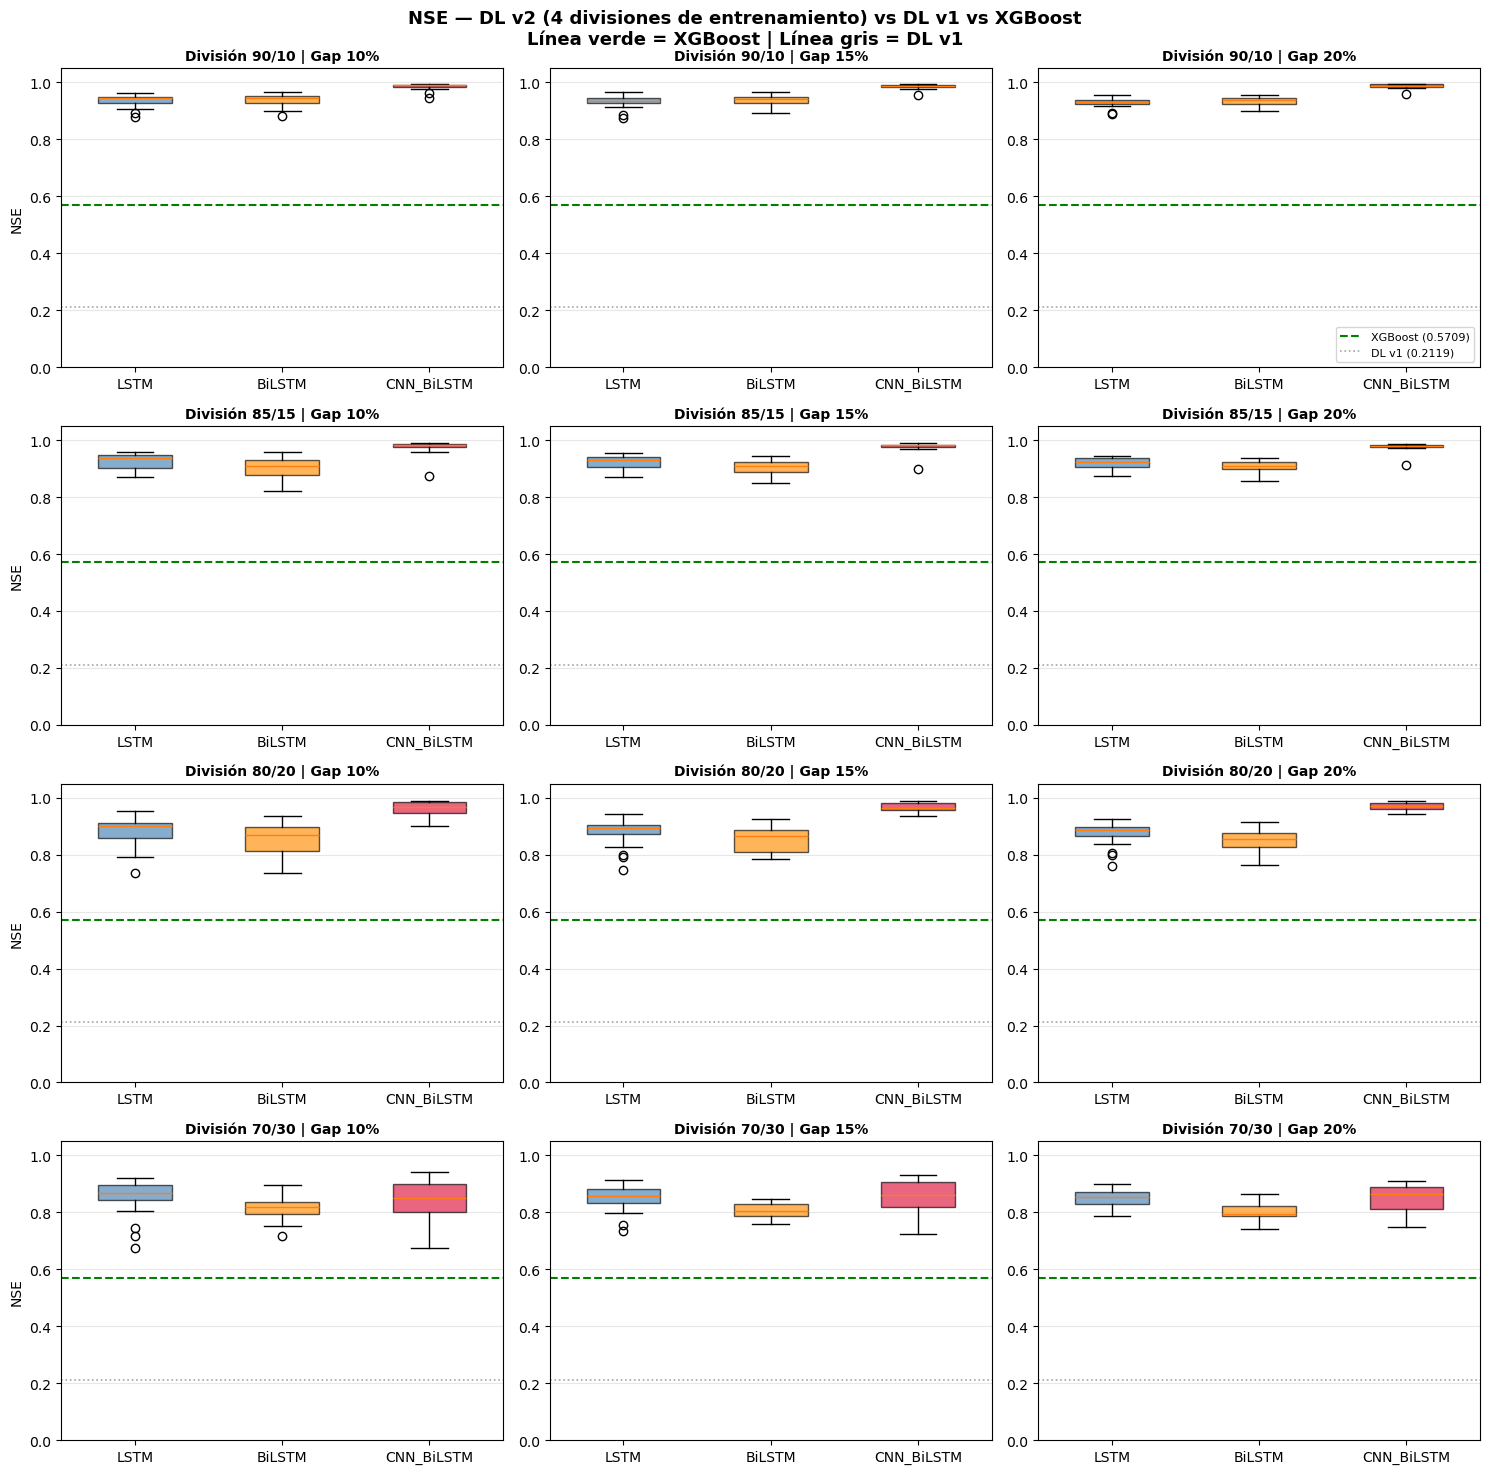

In [30]:
# ── Figura 1: NSE por división y pct_gap (4×3) ──────────────────────────────
fig, axes = plt.subplots(4, 3, figsize=(15, 15))
ref_xgb  = 0.5709
ref_v1   = 0.2119
colores  = {'LSTM_v2':'steelblue', 'BiLSTM_v2':'darkorange', 'CNN_BiLSTM_v2':'crimson'}

for row, div in enumerate(DIVISIONES):
    for col, pct in enumerate([10, 15, 20]):
        ax  = axes[row, col]
        sub = df_res_v2[(df_res_v2['division'] == div) & (df_res_v2['pct_gap'] == pct)]
        data   = [sub[sub['Modelo'] == m]['NSE'].values for m in colores]
        labels = [m.replace('_v2','') for m in colores]
        bp = ax.boxplot(data, labels=labels, patch_artist=True, widths=0.5)
        for patch, color in zip(bp['boxes'], colores.values()):
            patch.set_facecolor(color); patch.set_alpha(0.65)
        ax.axhline(ref_xgb, color='green', ls='--', lw=1.5, label=f'XGBoost ({ref_xgb})')
        ax.axhline(ref_v1,  color='gray',  ls=':',  lw=1.2, alpha=0.7, label=f'DL v1 ({ref_v1})')
        ax.set_title(f'División {div} | Gap {pct}%', fontweight='bold', fontsize=10)
        ax.set_ylabel('NSE' if col == 0 else '', fontsize=10)
        ax.set_ylim(0, 1.05)
        ax.grid(axis='y', alpha=0.3)
        if row == 0 and col == 2:
            ax.legend(fontsize=8, loc='lower right')

plt.suptitle(
    'NSE — DL v2 (4 divisiones de entrenamiento) vs DL v1 vs XGBoost\n'
    'Línea verde = XGBoost | Línea gris = DL v1',
    fontweight='bold', fontsize=13
)
plt.tight_layout()
plt.savefig('fig1_NSE_divisiones.png', dpi=150, bbox_inches='tight')
plt.show()


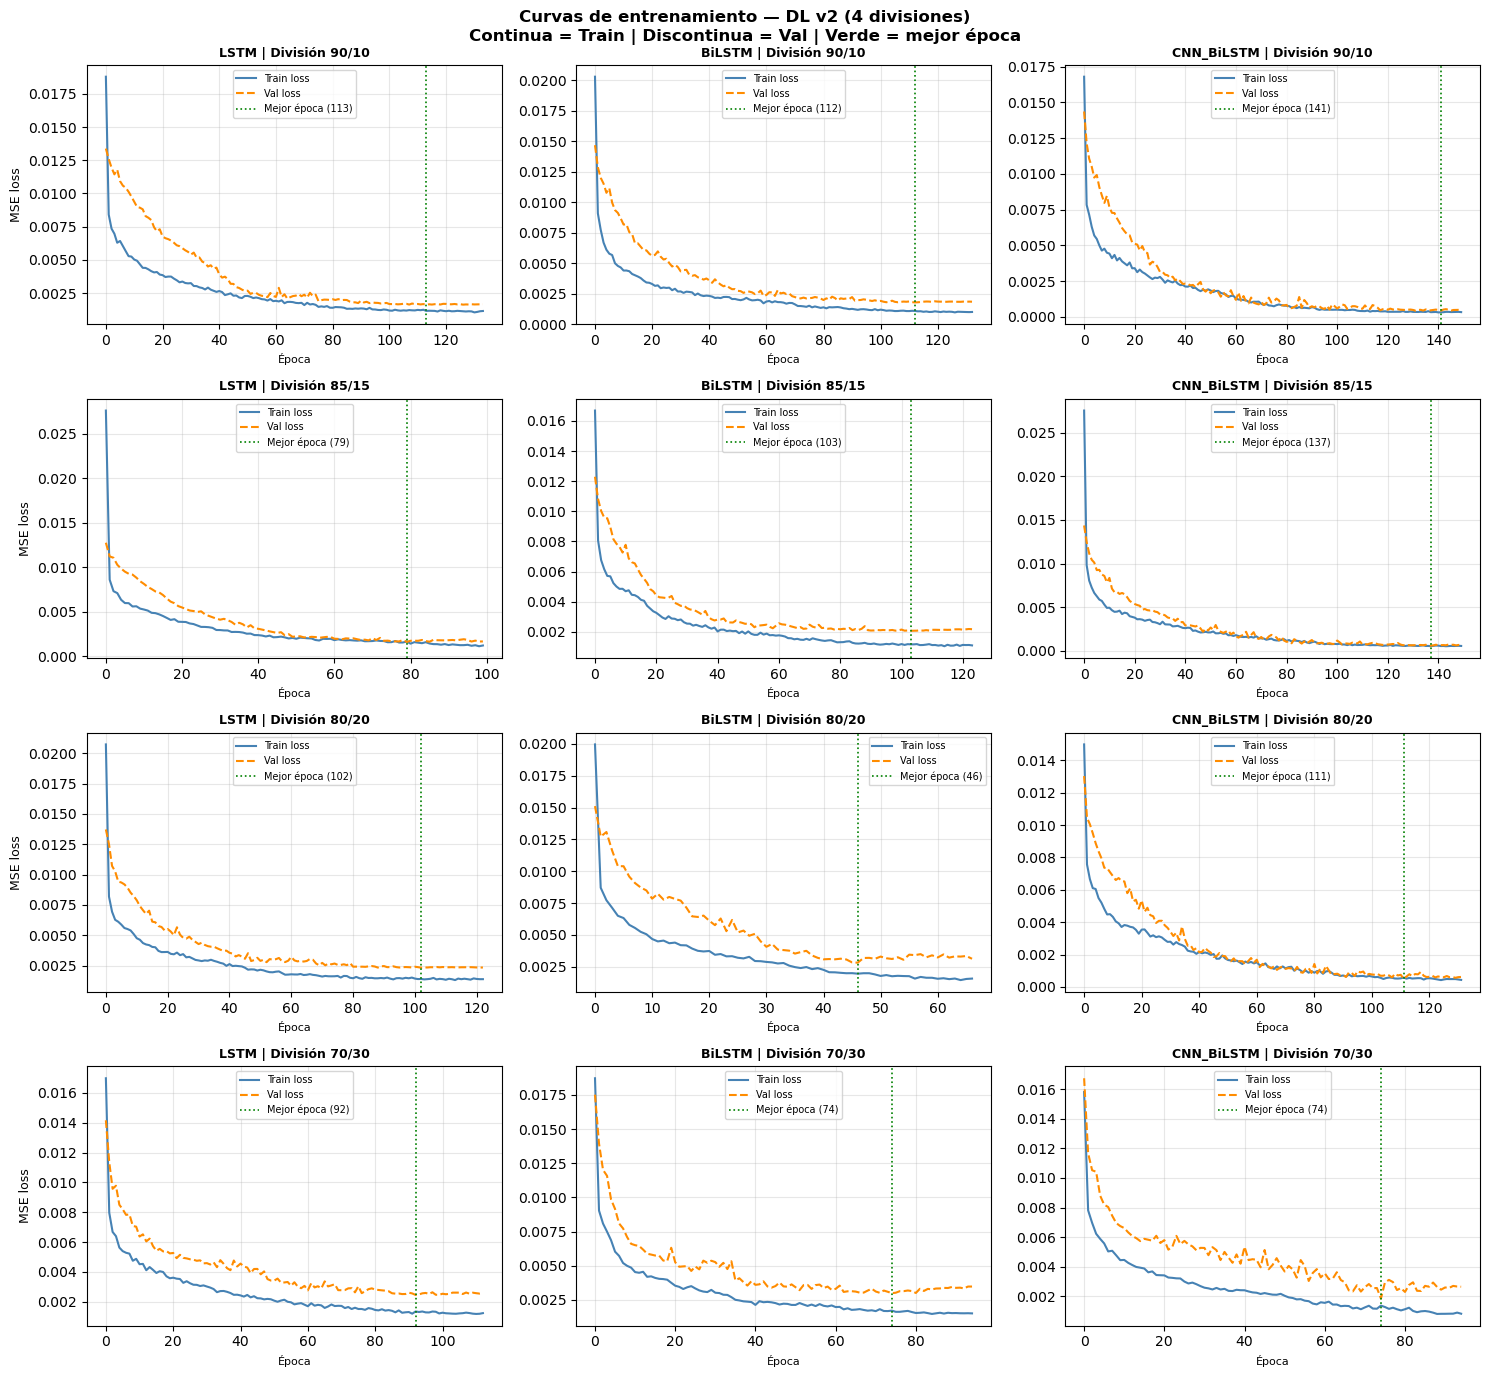

In [31]:
# ── Figura 2: Curvas de entrenamiento — 4 divisiones × 3 arquitecturas ───────
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
labels_split = {0.10: '90/10', 0.15: '85/15', 0.20: '80/20', 0.30: '70/30'}

for row, val_split in enumerate(VAL_SPLITS):
    for col, nombre_arq in enumerate(arquitecturas_v2):
        ax   = axes[row, col]
        hist = curvas_ent[(val_split, nombre_arq)]
        ax.plot(hist['loss'],     color='steelblue',   lw=1.5, label='Train loss')
        ax.plot(hist['val_loss'], color='darkorange',  lw=1.5, ls='--', label='Val loss')
        best_ep = np.argmin(hist['val_loss'])
        ax.axvline(best_ep, color='green', ls=':', lw=1.2,
                   label=f'Mejor época ({best_ep})')
        ax.set_title(
            f'{nombre_arq.replace("_v2","")} | División {labels_split[val_split]}',
            fontweight='bold', fontsize=9
        )
        ax.set_xlabel('Época', fontsize=8)
        ax.set_ylabel('MSE loss' if col == 0 else '', fontsize=9)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)

plt.suptitle(
    'Curvas de entrenamiento — DL v2 (4 divisiones)\n'
    'Continua = Train | Discontinua = Val | Verde = mejor época',
    fontweight='bold', fontsize=12
)
plt.tight_layout()
plt.savefig('fig2_curvas_entrenamiento_divisiones.png', dpi=150, bbox_inches='tight')
plt.show()


#### Experimento # 2. Gaps con hasta 3 días de valores faltantes sucesivos 🎯


In [32]:
# ===== EXPERIMENTO 2 — Gaps <= 3 dias consecutivos | 4 divisiones =====
# Reutiliza predicciones de PASO 7 — sin reentrenamiento
MAX_GAP_DIAS   = 3
PORCENTAJES_E2 = [0.10, 0.15, 0.20]
N_MASCARAS_E2  = 20

def crear_mascara_gaps_cortos(n_total, pct_objetivo, max_gap=3, seed=0):
    rng   = np.random.default_rng(seed)
    mask  = np.zeros(n_total, dtype=bool)
    n_obj = int(n_total * pct_objetivo)
    it    = 0
    while mask.sum() < n_obj and it < n_total * 20:
        inicio = rng.integers(0, n_total - max_gap)
        largo  = rng.integers(1, max_gap + 1)
        mask[inicio : inicio + largo] = True
        it += 1
    return mask

resultados_e2 = []
t0_e2 = time.time()

for val_split in VAL_SPLITS:
    train_pct = int(round((1 - val_split) * 100))
    val_pct   = int(round(val_split * 100))

    print('\n' + '#'*60)
    print('  DIVISION {}/{} - Gaps <= {} dias'.format(train_pct, val_pct, MAX_GAP_DIAS))
    print('#'*60)

    for nombre_arq in arquitecturas_v2:
        y_pred_all_log, y_true_all_log = predicciones[(val_split, nombre_arq)]

        _iter  = 0
        _total = len(PORCENTAJES_E2) * N_MASCARAS_E2
        print('  Procesando', nombre_arq)

        for pct in PORCENTAJES_E2:
            for seed in range(N_MASCARAS_E2):
                mask = crear_mascara_gaps_cortos(
                    len(fechas_all), pct, max_gap=MAX_GAP_DIAS, seed=seed
                )
                if mask.sum() < 5:
                    _iter += 1; continue

                gaps = contar_gaps(mask)
                m = calcular_metricas(
                    y_true_all_log[mask], y_pred_all_log[mask],
                    pct_gap=int(pct*100), modelo=nombre_arq
                )
                m['seed']           = seed
                m['val_split']      = val_split
                m['division']       = '{}/{}'.format(train_pct, val_pct)
                m['dias_recon']     = int(mask.sum())
                m['n_gaps']         = len(gaps)
                m['long_media_gap'] = round(np.mean(gaps), 2) if gaps else 0
                m['long_max_gap']   = int(np.max(gaps))       if gaps else 0
                resultados_e2.append(m)
                _iter += 1
                print('  Mascaras: {}/{}'.format(_iter, _total), end='\r')
        print('  Mascaras: {}/{} OK'.format(_total, _total))

df_res_e2 = pd.DataFrame(resultados_e2)
print('\nExperimento 2 completado en {:.1f} min'.format((time.time()-t0_e2)/60))
print('   {} evaluaciones — sin reentrenamiento'.format(len(df_res_e2)))

print('\nDIAS RECONSTRUIDOS — Gaps <= 3 dias consecutivos')
print('='*72)
print(
    df_res_e2.groupby('pct_gap')[['dias_recon','n_gaps','long_media_gap','long_max_gap']]
    .mean().round(2).to_string()
)

print('\nMETRICAS — Gaps <= 3 dias | por modelo y division')
print('='*80)
print(
    df_res_e2.groupby(['Modelo','division','pct_gap'])[metricas_cols]
    .agg(['mean','std']).round(4).to_string()
)

print('\nRanking NSE medio (gaps <= 3d, todos los pct_gap):')
print(
    df_res_e2.groupby(['division','Modelo'])['NSE']
    .mean().round(4).unstack('Modelo').to_string()
)

print('\nCOMPARACION NSE: aleatorio vs gaps <= 3d (Division 85/15)')
print('='*72)
nse_e1_ref = (
    df_res_v2[df_res_v2['division'] == '85/15']
    .groupby(['Modelo','pct_gap'])['NSE'].mean().round(4).rename('NSE_aleatorio')
)
nse_e2_ref = (
    df_res_e2[df_res_e2['division'] == '85/15']
    .groupby(['Modelo','pct_gap'])['NSE'].mean().round(4).rename('NSE_gaps<=3d')
)
df_comp = pd.concat([nse_e1_ref, nse_e2_ref], axis=1).reset_index()
df_comp['Delta_NSE'] = (df_comp['NSE_gaps<=3d'] - df_comp['NSE_aleatorio']).round(4)
print(df_comp.to_string(index=False))
print('  Delta NSE > 0 => gaps cortos son mas faciles de reconstruir')
print('='*72)

df_res_e2.to_excel('validacion_DL_v2_gaps_cortos.xlsx', index=False)
print('\n-> Exportado: validacion_DL_v2_gaps_cortos.xlsx')



############################################################
  DIVISION 90/10 - Gaps <= 3 dias
############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

############################################################
  DIVISION 85/15 - Gaps <= 3 dias
############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

############################################################
  DIVISION 80/20 - Gaps <= 3 dias
############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

############################################################
  DIVISION 70/30 - Gaps <= 3 dias
###############################

#### Experimento # 3. Gaps con hasta 100 días de valores consecutivos faltantes

In [33]:
# ===== EXPERIMENTO 3 — Gaps <= 100 días consecutivos | 4 divisiones =====
# Reutiliza predicciones del PASO 7 — sin reentrenamiento
# Escenario: huecos largos típicos de fallas de sensor o ausencia de operador
MAX_GAP_E3     = 100
PORCENTAJES_E3 = [0.10, 0.15, 0.20]
N_MASCARAS_E3  = 20

def crear_mascara_gaps_largos(n_total, pct_objetivo, max_gap=100, seed=0):
    'Genera mascara con bloques de hasta max_gap dias consecutivos.'
    rng   = np.random.default_rng(seed)
    mask  = np.zeros(n_total, dtype=bool)
    n_obj = int(n_total * pct_objetivo)
    it    = 0
    while mask.sum() < n_obj and it < n_total * 20:
        largo  = rng.integers(1, max_gap + 1)
        inicio = rng.integers(0, max(1, n_total - largo))
        mask[inicio : inicio + largo] = True
        it += 1
    return mask

resultados_e3 = []
t0_e3 = time.time()

for val_split in VAL_SPLITS:
    train_pct = int(round((1 - val_split) * 100))
    val_pct   = int(round(val_split * 100))

    print('\n' + '#'*62)
    print('  DIVISION {}/{} - Gaps <= {} dias'.format(train_pct, val_pct, MAX_GAP_E3))
    print('#'*62)

    for nombre_arq in arquitecturas_v2:
        y_pred_all_log, y_true_all_log = predicciones[(val_split, nombre_arq)]

        _iter  = 0
        _total = len(PORCENTAJES_E3) * N_MASCARAS_E3
        print('  Procesando', nombre_arq)

        for pct in PORCENTAJES_E3:
            for seed in range(N_MASCARAS_E3):
                mask = crear_mascara_gaps_largos(
                    len(fechas_all), pct, max_gap=MAX_GAP_E3, seed=seed
                )
                if mask.sum() < 5:
                    _iter += 1; continue

                gaps = contar_gaps(mask)
                m = calcular_metricas(
                    y_true_all_log[mask], y_pred_all_log[mask],
                    pct_gap=int(pct*100), modelo=nombre_arq
                )
                m['seed']           = seed
                m['val_split']      = val_split
                m['division']       = '{}/{}'.format(train_pct, val_pct)
                m['dias_recon']     = int(mask.sum())
                m['n_gaps']         = len(gaps)
                m['long_media_gap'] = round(np.mean(gaps), 2) if gaps else 0
                m['long_max_gap']   = int(np.max(gaps))       if gaps else 0
                resultados_e3.append(m)
                _iter += 1
                print('  Mascaras: {}/{}'.format(_iter, _total), end='\r')
        print('  Mascaras: {}/{} OK'.format(_total, _total))

df_res_e3 = pd.DataFrame(resultados_e3)
t_e3 = (time.time() - t0_e3) / 60
print('\n Experimento 3 completado en {:.1f} min'.format(t_e3))
print('   {} evaluaciones — sin reentrenamiento'.format(len(df_res_e3)))

print('\nDIAS RECONSTRUIDOS — Gaps <= 100 dias consecutivos')
print('='*72)
print(
    df_res_e3.groupby('pct_gap')[['dias_recon','n_gaps','long_media_gap','long_max_gap']]
    .mean().round(2).to_string()
)

print('\nMETRICAS — Gaps <= 100 dias | por modelo y division')
print('='*80)
print(
    df_res_e3.groupby(['Modelo','division','pct_gap'])[metricas_cols]
    .agg(['mean','std']).round(4).to_string()
)



##############################################################
  DIVISION 90/10 - Gaps <= 100 dias
##############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

##############################################################
  DIVISION 85/15 - Gaps <= 100 dias
##############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

##############################################################
  DIVISION 80/20 - Gaps <= 100 dias
##############################################################
  Procesando LSTM_v2
  Mascaras: 60/60 OK
  Procesando BiLSTM_v2
  Mascaras: 60/60 OK
  Procesando CNN_BiLSTM_v2
  Mascaras: 60/60 OK

##############################################################
  DIVISION 70/30 - Gaps <= 100 dias
#########

#### Comparación integrada — Experimento 1 vs Experimento 2 vs Experimento 3

In [34]:
# ===== COMPARACION INTEGRADA — Exp 1 | Exp 2 | Exp 3 =====
# Exp 1: Gaps aleatorios (df_res_v2)
# Exp 2: Gaps <=  3 dias consecutivos (df_res_e2)
# Exp 3: Gaps <= 100 dias consecutivos (df_res_e3)

df_e1 = df_res_v2.copy();  df_e1['Experimento'] = 'Exp1 (aleatorio)'
df_e2 = df_res_e2.copy();  df_e2['Experimento'] = 'Exp2 (<=3d)'
df_e3 = df_res_e3.copy();  df_e3['Experimento'] = 'Exp3 (<=100d)'
df_all = pd.concat([df_e1, df_e2, df_e3], ignore_index=True)

print('\n' + '='*100)
print('COMPARACION INTEGRADA — 3 Experimentos x 4 Divisiones x 3 Porcentajes de Gap')
print('='*100)
print('  Evaluaciones totales: {:,}  ({:,} Exp1 + {:,} Exp2 + {:,} Exp3)'.format(
    len(df_all), len(df_e1), len(df_e2), len(df_e3)))

print('\n-- TABLA 1: NSE medio por Experimento x Division x Gap --')
t1 = (df_all.groupby(['Experimento','division','pct_gap'])['NSE']
      .mean().round(4).unstack('pct_gap'))
t1.columns = ['Gap {}%'.format(c) for c in t1.columns]
print(t1.to_string())

print('\n-- TABLA 2: NSE por Modelo x Experimento  (Division 85/15 | Gap 10%) --')
t2 = (df_all[(df_all['division']=='85/15') & (df_all['pct_gap']==10)]
      .groupby(['Modelo','Experimento'])['NSE']
      .mean().round(4).unstack('Experimento'))
cols_orden = [c for c in ['Exp1 (aleatorio)','Exp2 (<=3d)','Exp3 (<=100d)'] if c in t2.columns]
t2 = t2[cols_orden]
print(t2.to_string())

print('\n-- TABLA 3: Metricas completas — mejor modelo x experimento (div 85/15, gap 10%)')
print('='*90)
for exp_label in ['Exp1 (aleatorio)', 'Exp2 (<=3d)', 'Exp3 (<=100d)']:
    sub = df_all[(df_all['Experimento']==exp_label) &
                 (df_all['division']=='85/15') &
                 (df_all['pct_gap']==10)]
    mejor = sub.groupby('Modelo')['NSE'].mean().idxmax()
    row   = sub[sub['Modelo']==mejor][metricas_cols].mean().round(4)
    print('\n  {}  ->  Mejor modelo: {}'.format(exp_label, mejor))
    print('    NSE={}  KGE={}  MAE={:.4f}  RMSE={:.4f}  R2={}  PBIAS={:.2f}%'.format(
        row['NSE'], row['KGE'], row['MAE'], row['RMSE'], row['R²'], row['PBIAS']))
print('='*90)

print('\n-- TABLA 4: NSE medio x Experimento x Gap%  (Division 85/15, todos modelos) --')
t4 = (df_all[df_all['division']=='85/15']
      .groupby(['Experimento','pct_gap'])['NSE']
      .mean().round(4).unstack('pct_gap'))
t4.columns = ['Gap {}%'.format(c) for c in t4.columns]
print(t4.to_string())

print('\n-- TABLA 5: NSE medio x Experimento x Division  (Gap 10%, todos modelos) --')
t5 = (df_all[df_all['pct_gap']==10]
      .groupby(['Experimento','division'])['NSE']
      .mean().round(4).unstack('division'))
div_order = [d for d in ['90/10','85/15','80/20','70/30'] if d in t5.columns]
t5 = t5[div_order]
print(t5.to_string())

print('\n-- TABLA 6: Delta NSE respecto a Exp1 (impacto de la estructura del gap) --')
base = (df_all[(df_all['Experimento']=='Exp1 (aleatorio)') & (df_all['division']=='85/15')]
        .groupby(['Modelo','pct_gap'])['NSE'].mean())
for exp_label in ['Exp2 (<=3d)', 'Exp3 (<=100d)']:
    comp  = (df_all[(df_all['Experimento']==exp_label) & (df_all['division']=='85/15')]
             .groupby(['Modelo','pct_gap'])['NSE'].mean())
    delta = (comp - base).round(4).unstack('pct_gap')
    delta.columns = ['Delta Gap {}%'.format(c) for c in delta.columns]
    print('\n  {}:'.format(exp_label))
    print(delta.to_string())

print('\n' + '='*100)

with pd.ExcelWriter('comparacion_integrada_experimentos_Santander.xlsx', engine='openpyxl') as writer:
    df_e1.to_excel(writer, sheet_name='Exp1_aleatorio',  index=False)
    df_e2.to_excel(writer, sheet_name='Exp2_gap3d',      index=False)
    df_e3.to_excel(writer, sheet_name='Exp3_gap100d',    index=False)
    df_all.to_excel(writer, sheet_name='Todos',          index=False)
    t1.to_excel(writer, sheet_name='NSE_Exp_Div_Gap')
    t2.to_excel(writer, sheet_name='NSE_Modelo_Exp')
    t5.to_excel(writer, sheet_name='NSE_Exp_Division')

print('-> Exportado: comparacion_integrada_experimentos_Santander.xlsx (7 hojas)')



COMPARACION INTEGRADA — 3 Experimentos x 4 Divisiones x 3 Porcentajes de Gap
  Evaluaciones totales: 2,160  (720 Exp1 + 720 Exp2 + 720 Exp3)

-- TABLA 1: NSE medio por Experimento x Division x Gap --
                           Gap 10%  Gap 15%  Gap 20%
Experimento      division                           
Exp1 (aleatorio) 70/30      0.8325   0.8365   0.8337
                 80/20      0.8979   0.8998   0.8977
                 85/15      0.9342   0.9355   0.9350
                 90/10      0.9534   0.9525   0.9507
Exp2 (<=3d)      70/30      0.8247   0.8237   0.8210
                 80/20      0.8865   0.8847   0.8875
                 85/15      0.9306   0.9304   0.9314
                 90/10      0.9483   0.9479   0.9477
Exp3 (<=100d)    70/30      0.7954   0.7919   0.7913
                 80/20      0.8517   0.8513   0.8593
                 85/15      0.9096   0.9059   0.9123
                 90/10      0.9373   0.9321   0.9374

-- TABLA 2: NSE por Modelo x Experimento  (Division 85/1

#### Figura — Distribución visual de gaps


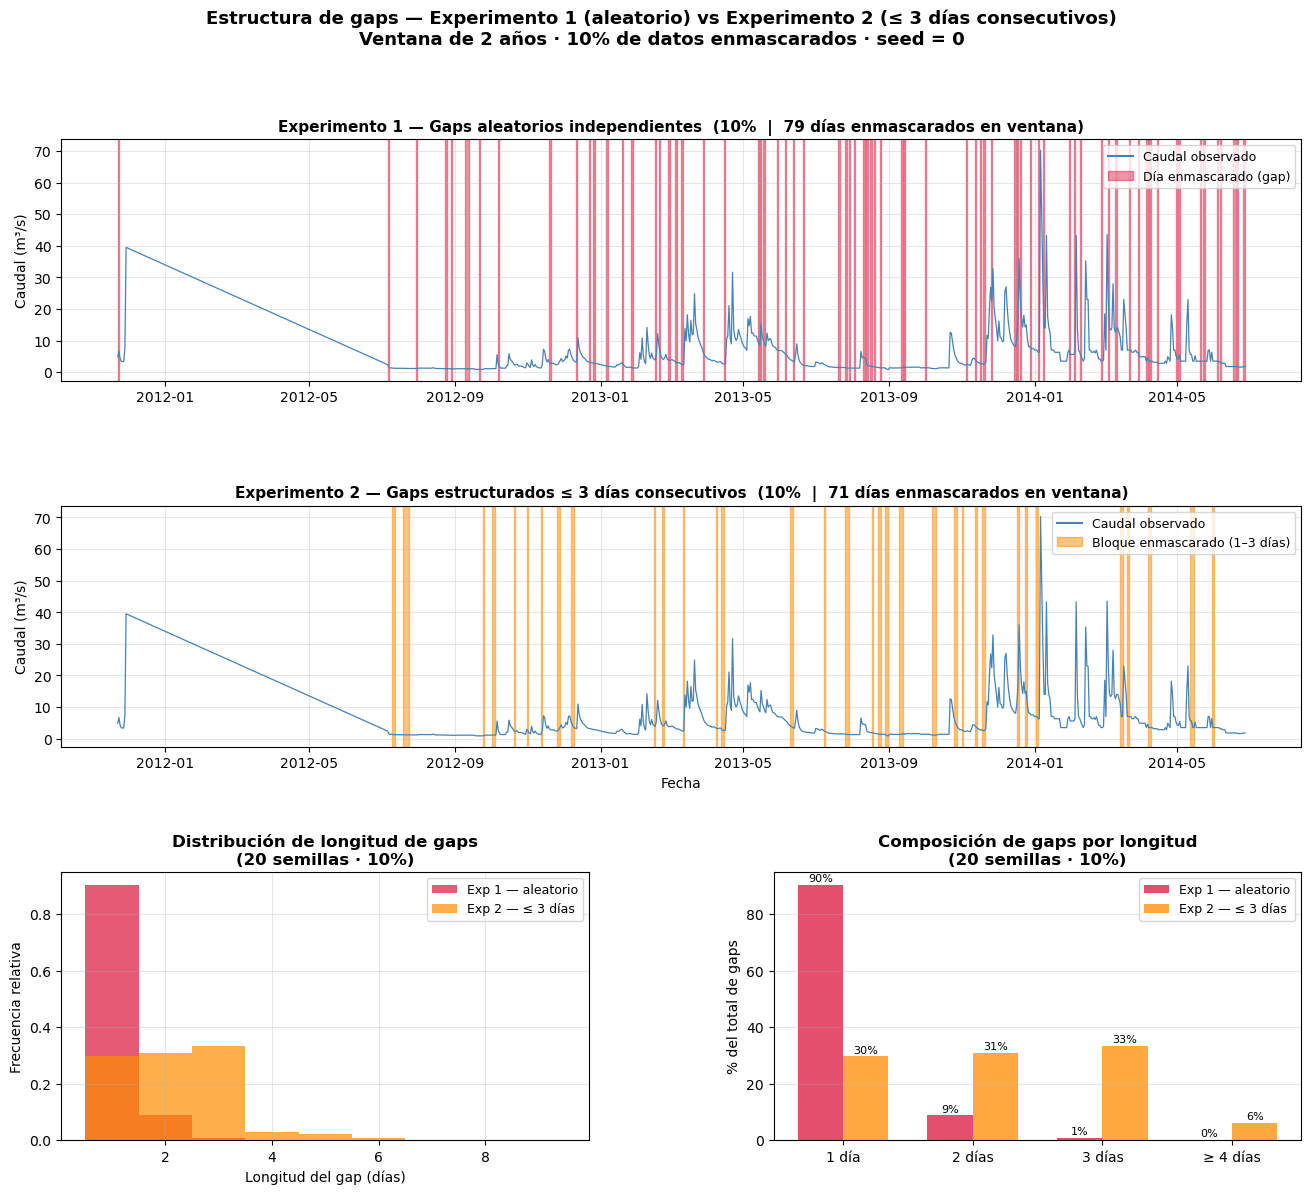

In [35]:
# ── Figura 5: Estructura de gaps — Exp 1 (aleatorio) vs Exp 2 (≤ 3 días) ────
from itertools import groupby as _grp
from matplotlib.patches import Patch

SEED_VIZ  = 0
PCT_VIZ   = 0.10
N         = len(fechas_all)
fechas_dt = pd.to_datetime(fechas_all)

rng_e1  = np.random.default_rng(SEED_VIZ)
mask_e1 = rng_e1.random(N) < PCT_VIZ
mask_e2 = crear_mascara_gaps_cortos(N, PCT_VIZ, max_gap=3, seed=SEED_VIZ)

gaps_e1_all, gaps_e2_all = [], []
for s in range(N_MASCARAS):
    gaps_e1_all.extend(contar_gaps(np.random.default_rng(s).random(N) < PCT_VIZ))
    gaps_e2_all.extend(contar_gaps(crear_mascara_gaps_cortos(N, PCT_VIZ, max_gap=3, seed=s)))

obs_vals = np.expm1(np.clip(
    scaler_y.inverse_transform(y_all.reshape(-1, 1)).flatten(), 0, 20
))

ini, fin = 600, 1330
f_zoom   = fechas_dt[ini:fin]
q_zoom   = obs_vals[ini:fin]
m1_zoom  = mask_e1[ini:fin]
m2_zoom  = mask_e2[ini:fin]

def sombrear_gaps(ax, fechas, mask, color, alpha=0.4):
    for val, grp in _grp(enumerate(mask), key=lambda x: x[1]):
        if val:
            idxs = [i for i, _ in grp]
            f0 = fechas[idxs[0]]
            f1 = fechas[min(idxs[-1]+1, len(fechas)-1)]
            ax.axvspan(f0, f1, color=color, alpha=alpha, zorder=1)

fig = plt.figure(figsize=(16, 13))
gs  = fig.add_gridspec(3, 2, height_ratios=[1.8, 1.8, 2], hspace=0.5, wspace=0.35)
ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, :])
ax3 = fig.add_subplot(gs[2, 0])
ax4 = fig.add_subplot(gs[2, 1])

ax1.plot(f_zoom, q_zoom, color='steelblue', lw=0.9, zorder=2)
sombrear_gaps(ax1, f_zoom, m1_zoom, color='crimson', alpha=0.45)
ax1.set_title(
    'Experimento 1 — Gaps aleatorios independientes  '
    '(10%  |  {} días enmascarados en ventana)'.format(m1_zoom.sum()),
    fontweight='bold', fontsize=11
)
ax1.set_ylabel('Caudal (m³/s)', fontsize=10)
ax1.grid(alpha=0.3)
ax1.legend(handles=[
    plt.Line2D([0],[0], color='steelblue', lw=1.5, label='Caudal observado'),
    Patch(color='crimson', alpha=0.45, label='Día enmascarado (gap)'),
], fontsize=9, loc='upper right')

ax2.plot(f_zoom, q_zoom, color='steelblue', lw=0.9, zorder=2)
sombrear_gaps(ax2, f_zoom, m2_zoom, color='darkorange', alpha=0.5)
ax2.set_title(
    'Experimento 2 — Gaps estructurados ≤ 3 días consecutivos  '
    '(10%  |  {} días enmascarados en ventana)'.format(m2_zoom.sum()),
    fontweight='bold', fontsize=11
)
ax2.set_ylabel('Caudal (m³/s)', fontsize=10)
ax2.set_xlabel('Fecha', fontsize=10)
ax2.grid(alpha=0.3)
ax2.legend(handles=[
    plt.Line2D([0],[0], color='steelblue', lw=1.5, label='Caudal observado'),
    Patch(color='darkorange', alpha=0.5, label='Bloque enmascarado (1–3 días)'),
], fontsize=9, loc='upper right')

max_g = max(max(gaps_e1_all), max(gaps_e2_all))
bins  = np.arange(0.5, min(max_g, 12) + 1.5, 1)
ax3.hist(gaps_e1_all, bins=bins, color='crimson',    alpha=0.7, density=True, label='Exp 1 — aleatorio')
ax3.hist(gaps_e2_all, bins=bins, color='darkorange', alpha=0.7, density=True, label='Exp 2 — ≤ 3 días')
ax3.set_xlabel('Longitud del gap (días)', fontsize=10)
ax3.set_ylabel('Frecuencia relativa', fontsize=10)
ax3.set_title('Distribución de longitud de gaps\n(20 semillas · 10%)', fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.3)

cats   = ['1 día', '2 días', '3 días', '≥ 4 días']
t1, t2 = len(gaps_e1_all), len(gaps_e2_all)
pct_e1 = [sum(1 for g in gaps_e1_all if g == k)/t1*100 for k in [1,2,3]] + \
         [sum(1 for g in gaps_e1_all if g >= 4)/t1*100]
pct_e2 = [sum(1 for g in gaps_e2_all if g == k)/t2*100 for k in [1,2,3]] + \
         [sum(1 for g in gaps_e2_all if g >= 4)/t2*100]
x, w   = np.arange(4), 0.35
bars1  = ax4.bar(x - w/2, pct_e1, w, color='crimson',    alpha=0.75, label='Exp 1 — aleatorio')
bars2  = ax4.bar(x + w/2, pct_e2, w, color='darkorange', alpha=0.75, label='Exp 2 — ≤ 3 días')
for bar in list(bars1) + list(bars2):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             '{:.0f}%'.format(bar.get_height()), ha='center', va='bottom', fontsize=8)
ax4.set_xticks(x); ax4.set_xticklabels(cats, fontsize=10)
ax4.set_ylabel('% del total de gaps', fontsize=10)
ax4.set_title('Composición de gaps por longitud\n(20 semillas · 10%)', fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(axis='y', alpha=0.3)

plt.suptitle(
    'Estructura de gaps — Experimento 1 (aleatorio) vs Experimento 2 (≤ 3 días consecutivos)\n'
    'Ventana de 2 años · 10% de datos enmascarados · seed = 0',
    fontweight='bold', fontsize=13
)
plt.savefig('fig5_estructura_gaps_comparacion.png', dpi=150, bbox_inches='tight')
plt.show()


In [36]:
# Tabla de frecuencia absoluta de longitud de gaps
max_gap_tabla = max(max(gaps_e1_all), max(gaps_e2_all))
longitudes = list(range(1, max_gap_tabla + 1))

freq_e1 = [gaps_e1_all.count(k) for k in longitudes]
freq_e2 = [gaps_e2_all.count(k) for k in longitudes]

df_gaps = pd.DataFrame({
    'Longitud del gap (días)': longitudes,
    'Exp 1 — Aleatorio (frec. abs.)': freq_e1,
    'Exp 2 — ≤ 3 días (frec. abs.)': freq_e2,
})

df_gaps = df_gaps[(df_gaps['Exp 1 — Aleatorio (frec. abs.)'] > 0) |
                  (df_gaps['Exp 2 — ≤ 3 días (frec. abs.)'] > 0)].reset_index(drop=True)

df_gaps.style.set_caption('Frecuencia absoluta de longitud de gaps (20 semillas · 10%)')\
             .set_table_styles([{'selector': 'caption',
                                  'props': [('font-weight', 'bold'), ('font-size', '13px')]}])\
             .hide(axis='index')


Longitud del gap (días),Exp 1 — Aleatorio (frec. abs.),Exp 2 — ≤ 3 días (frec. abs.)
1,4432,728
2,432,758
3,40,818
4,5,75
5,0,54
6,0,19
7,0,1
8,0,2
9,0,1


In [37]:
# Tabla de frecuencia absoluta de longitud de gaps — 10%, 15% y 20%
from IPython.display import display

for pct_viz in [0.10, 0.15, 0.20]:
    gaps_e1 = []
    gaps_e2 = []
    for s in range(N_MASCARAS):
        gaps_e1.extend(contar_gaps(np.random.default_rng(s).random(N) < pct_viz))
        gaps_e2.extend(contar_gaps(crear_mascara_gaps_cortos(N, pct_viz, max_gap=3, seed=s)))

    max_gap_t = max(max(gaps_e1), max(gaps_e2))
    longs = list(range(1, max_gap_t + 1))

    df_g = pd.DataFrame({
        'Longitud del gap (dias)':        longs,
        'Exp 1 — Aleatorio (frec. abs.)': [gaps_e1.count(k) for k in longs],
        'Exp 2 — <=3 dias (frec. abs.)':  [gaps_e2.count(k) for k in longs],
    })
    df_g = df_g[(df_g['Exp 1 — Aleatorio (frec. abs.)'] > 0) |
                (df_g['Exp 2 — <=3 dias (frec. abs.)'] > 0)].reset_index(drop=True)

    display(
        df_g.style
        .set_caption('Frecuencia absoluta de longitud de gaps (20 semillas · {}%)'.format(int(pct_viz*100)))
        .set_table_styles([{'selector': 'caption',
                            'props': [('font-weight', 'bold'), ('font-size', '13px')]}])
        .hide(axis='index')
    )


Longitud del gap (dias),Exp 1 — Aleatorio (frec. abs.),Exp 2 — <=3 dias (frec. abs.)
1,4432,728
2,432,758
3,40,818
4,5,75
5,0,54
6,0,19
7,0,1
8,0,2
9,0,1


Longitud del gap (dias),Exp 1 — Aleatorio (frec. abs.),Exp 2 — <=3 dias (frec. abs.)
1,5948,1024
2,900,1054
3,121,1168
4,14,153
5,1,90
6,0,49
7,0,13
8,0,4
9,0,2


Longitud del gap (dias),Exp 1 — Aleatorio (frec. abs.),Exp 2 — <=3 dias (frec. abs.)
1,7022,1244
2,1394,1307
3,260,1428
4,51,260
5,9,155
6,2,83
7,1,26
8,0,11
9,0,8
10,0,1


#### Nueva Figura 3 — Serie con panel de error

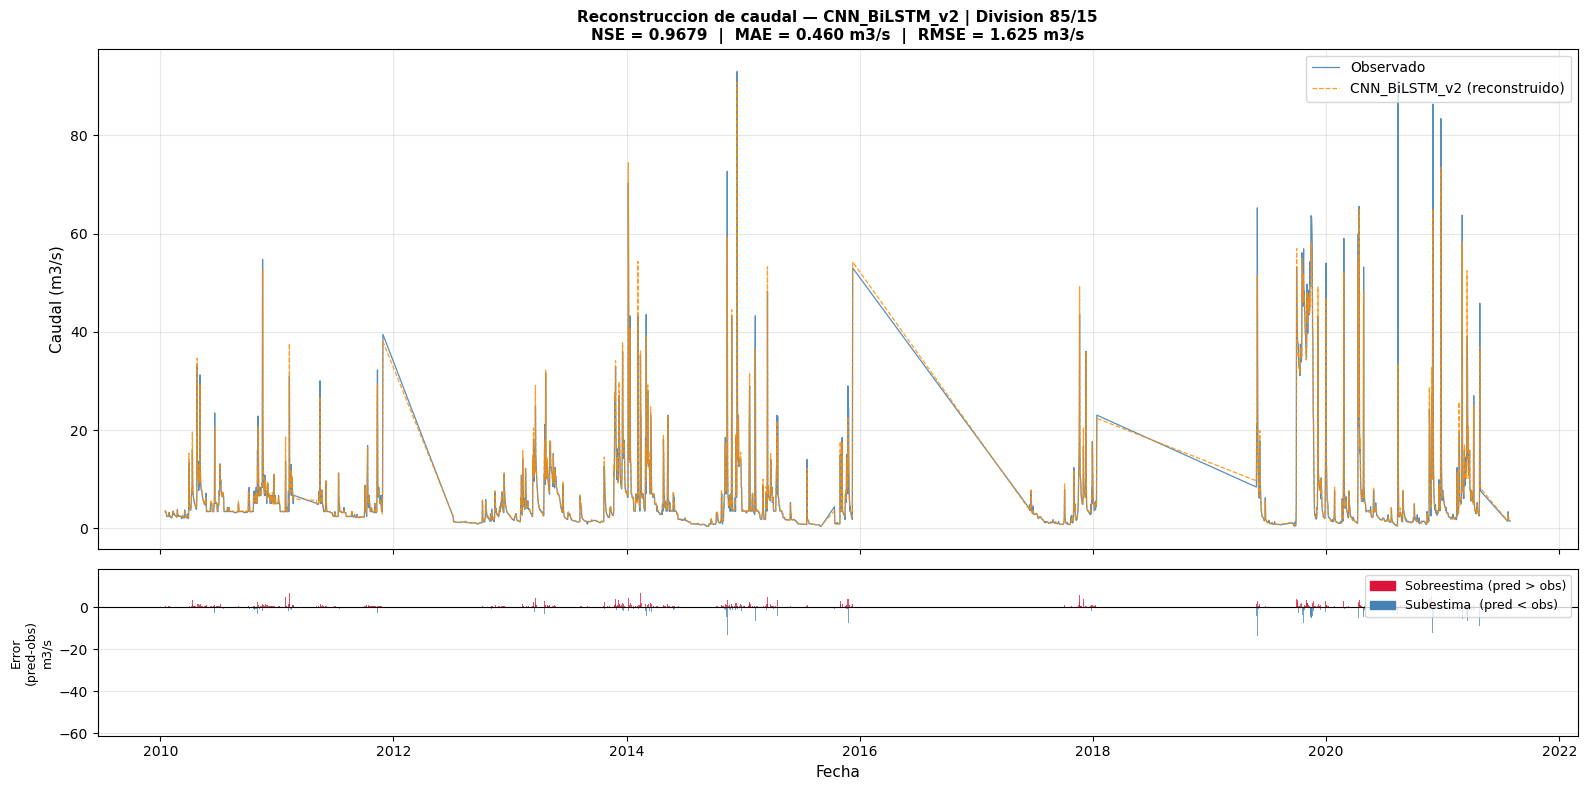

In [38]:
# Figura 3: Serie temporal observado vs reconstruido + panel de error
# Usa predicciones del mejor modelo (85/15) — no requiere model_final
arq_plot = nse_rank_v2.index[0]
vs_plot  = 0.15

y_pred_f_log, y_true_f_log = predicciones[(vs_plot, arq_plot)]

obs_f  = np.expm1(np.clip(y_true_f_log, 0, 20))
pred_f = np.maximum(np.expm1(np.clip(y_pred_f_log, 0, 20)), 0)
error_f   = pred_f - obs_f
fechas_dt = pd.to_datetime(fechas_all)

from sklearn.metrics import mean_absolute_error, mean_squared_error
nse_f  = NSE(obs_f, pred_f)
mae_f  = mean_absolute_error(obs_f, pred_f)
rmse_f = np.sqrt(mean_squared_error(obs_f, pred_f))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(16, 8), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

ax1.plot(fechas_dt, obs_f,  color='steelblue',  lw=0.9, label='Observado', alpha=0.9, zorder=2)
ax1.plot(fechas_dt, pred_f, color='darkorange', lw=0.9, ls='--',
         label='{} (reconstruido)'.format(arq_plot), alpha=0.85, zorder=3)
ax1.set_ylabel('Caudal (m3/s)', fontsize=11)
ax1.legend(fontsize=10, loc='upper right')
ax1.grid(alpha=0.3)
ax1.set_title(
    'Reconstruccion de caudal — {} | Division 85/15\n'
    'NSE = {:.4f}  |  MAE = {:.3f} m3/s  |  RMSE = {:.3f} m3/s'.format(
        arq_plot, nse_f, mae_f, rmse_f),
    fontweight='bold', fontsize=11
)

colores_err = ['crimson' if e >= 0 else 'steelblue' for e in error_f]
ax2.bar(fechas_dt, error_f, color=colores_err, width=2, alpha=0.75)
ax2.axhline(0, color='black', lw=0.8)
ax2.set_ylabel('Error\n(pred-obs)\nm3/s', fontsize=9)
ax2.set_xlabel('Fecha', fontsize=11)
ax2.grid(axis='y', alpha=0.3)

from matplotlib.patches import Patch
ax2.legend(handles=[
    Patch(color='crimson',   label='Sobreestima (pred > obs)'),
    Patch(color='steelblue', label='Subestima  (pred < obs)'),
], fontsize=9, loc='upper right')

plt.tight_layout()
plt.savefig('fig3_serie_error.png', dpi=150, bbox_inches='tight')
plt.show()


## 💾 PASO 9 — Reconstrucción final + exportación

In [39]:
mejor_arq_v2 = nse_rank_v2.index[0]
mejor_nse_v2 = nse_rank_v2.iloc[0]
print(f'🏆 Mejor arquitectura v2: {mejor_arq_v2} (NSE={mejor_nse_v2:.4f})')

# Comparar con XGBoost
delta = mejor_nse_v2 - 0.5709
if   delta >  0.02: concl = '✅ DL v2 SUPERA al ML clásico'
elif delta > -0.02: concl = '🟡 DL v2 comparable al ML clásico'
else:               concl = '🟠 ML clásico sigue siendo mejor (Gao et al. 2026)'
print(f'   vs XGBoost (0.5709): Δ = {delta:+.4f} → {concl}')

# Mejora vs v1
nse_v1 = 0.2119
print(f'   Mejora vs DL v1:     Δ = {mejor_nse_v2 - nse_v1:+.4f} '
      f'({(mejor_nse_v2 - nse_v1)/nse_v1*100:+.1f}%)')

🏆 Mejor arquitectura v2: CNN_BiLSTM_v2 (NSE=0.9765)
   vs XGBoost (0.5709): Δ = +0.4056 → ✅ DL v2 SUPERA al ML clásico
   Mejora vs DL v1:     Δ = +0.7646 (+360.8%)


In [40]:
# Reentrenar modelo final con TODOS los datos
import os

MODEL_PATH    = '../modelos/modelo_cnn_bilstm_v2_Santander.keras'
FORCE_RETRAIN = False

if os.path.exists(MODEL_PATH) and not FORCE_RETRAIN:
    model_final = tf.keras.models.load_model(MODEL_PATH)
    print('Modelo cargado desde cache: {}'.format(MODEL_PATH))
else:
    print('Entrenando {} final...'.format(mejor_arq_v2))
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    hp_final = HP_OPTIMOS[mejor_arq_v2]
    if mejor_arq_v2 == 'CNN_BiLSTM_v2':
        model_final = arquitecturas_v2[mejor_arq_v2](
            input_shape,
            units=hp_final['units'], dropout=hp_final['dropout'],
            filters=hp_final['filters'], kernel_size=hp_final['kernel_size'],
            dense_units=hp_final['dense_units'])
    else:
        model_final = arquitecturas_v2[mejor_arq_v2](
            input_shape,
            units=hp_final['units'], dropout=hp_final['dropout'],
            dense_units=hp_final['dense_units'])
    model_final.compile(optimizer=Adam(learning_rate=hp_final['learning_rate']), loss='mse')
    model_final.fit(X_all, y_all, epochs=200, batch_size=BATCH_SIZE,
                    validation_split=0.10,
                    callbacks=get_callbacks(patience_es=25, patience_lr=12), verbose=1)
    model_final.save(MODEL_PATH)
    print('Modelo guardado: {}'.format(MODEL_PATH))

# Reconstruccion - gaps <= 100 dias
UMBRAL_RECON = 100

def _get_mask_gaps(serie, umbral=100):
    mask = pd.Series(False, index=serie.index)
    en_gap, inicio = False, None
    for fecha, valor in serie.items():
        if pd.isna(valor):
            if not en_gap:
                inicio, en_gap = fecha, True
        else:
            if en_gap:
                if (fecha - inicio).days <= umbral:
                    mask[inicio:fecha] = True
                en_gap = False
    if en_gap and inicio is not None:
        fin = serie.index[-1]
        if (fin - inicio).days <= umbral:
            mask[inicio:fin] = True
    return mask

serie_caudal = df_full[TARGET]
mask_rec     = _get_mask_gaps(serie_caudal, umbral=UMBRAL_RECON) & serie_caudal.isna()
arr_sc       = scaler_X.transform(df_full[FEATURES_V2].values.astype(np.float32))
total_len    = WINDOW + HORIZON + 1
pred_seqs, pred_fechas = [], []
for i in range(WINDOW, len(df_full) - HORIZON):
    fecha = df_full.index[i]
    if not mask_rec.get(fecha, False):
        continue
    seq = arr_sc[i - WINDOW : i + HORIZON + 1]
    if seq.shape[0] == total_len:
        pred_seqs.append(seq)
        pred_fechas.append(fecha)
print('Secuencias a reconstruir: {}'.format(len(pred_seqs)))
Q_rec  = serie_caudal.values.copy().astype(float)
fuente = np.array(['Observado'] * len(df_full), dtype=object)
if pred_seqs:
    y_sc  = model_final.predict(np.array(pred_seqs, dtype=np.float32), verbose=0).flatten()
    y_m3s = np.maximum(np.expm1(scaler_y.inverse_transform(y_sc.reshape(-1,1)).flatten()), 0)
    for fecha, val in zip(pred_fechas, y_m3s):
        idx = df_full.index.get_loc(fecha)
        Q_rec[idx] = val
        fuente[idx] = 'Reconstruido ({})'.format(mejor_arq_v2)
for i, fecha in enumerate(df_full.index):
    if serie_caudal.isna().get(fecha, False) and not mask_rec.get(fecha, False):
        fuente[i] = 'No reconstruido (gap >100d)'
df_final = pd.DataFrame({'Caudal_m3s': Q_rec, 'Fuente': fuente}, index=df_full.index)
print(df_final['Fuente'].value_counts().to_string())


Entrenando CNN_BiLSTM_v2 final...
Epoch 1/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - loss: 0.0147 - val_loss: 0.0138 - learning_rate: 0.0010
Epoch 2/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0085 - val_loss: 0.0124 - learning_rate: 0.0010
Epoch 3/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0070 - val_loss: 0.0112 - learning_rate: 0.0010
Epoch 4/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0064 - val_loss: 0.0113 - learning_rate: 0.0010
Epoch 5/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0057 - val_loss: 0.0105 - learning_rate: 0.0010
Epoch 6/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0053 - val_loss: 0.0089 - learning_rate: 0.0010
Epoch 7/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0049 - val_loss: 0.0084 - learning_rate: 0.0010
Epoch 8/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0047 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 9/200
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0046 - val_loss: 0.0075 

#### Serie completa con reconstrucción

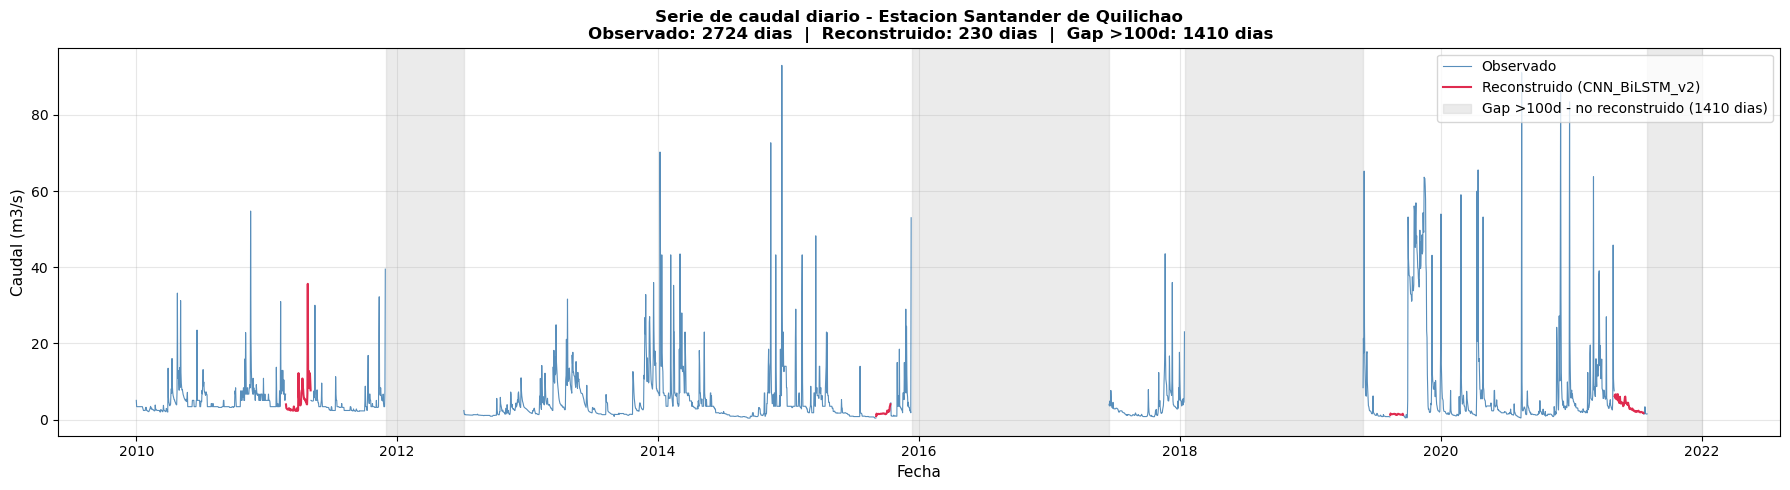

In [41]:
# Figura 4: Serie completa - observado + reconstruido
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
obs_mask  = df_final['Fuente'] == 'Observado'
rec_mask  = df_final['Fuente'].str.startswith('Reconstruido')
nrec_mask = df_final['Fuente'].str.startswith('No recon')
fig, ax = plt.subplots(figsize=(18, 5))
ax.plot(df_final.index, df_final['Caudal_m3s'].where(obs_mask),
        color='steelblue', lw=0.8, label='Observado', alpha=0.9, zorder=2)
ax.plot(df_final.index, df_final['Caudal_m3s'].where(rec_mask),
        color='crimson', lw=1.5,
        label='Reconstruido ({})'.format(mejor_arq_v2), alpha=0.9, zorder=3)
in_gap = False
for fecha, flag in nrec_mask.items():
    if flag and not in_gap:
        gap_ini = fecha; in_gap = True
    elif not flag and in_gap:
        ax.axvspan(gap_ini, fecha, color='lightgray', alpha=0.45, zorder=0)
        in_gap = False
if in_gap:
    ax.axvspan(gap_ini, df_final.index[-1], color='lightgray', alpha=0.45, zorder=0)
n_obs  = int(obs_mask.sum())
n_rec  = int(rec_mask.sum())
n_nrec = int(nrec_mask.sum())
handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(color='lightgray', alpha=0.45,
                     label='Gap >100d - no reconstruido ({} dias)'.format(n_nrec)))
ax.legend(handles=handles, fontsize=10, loc='upper right')
ax.set_xlabel('Fecha', fontsize=11)
ax.set_ylabel('Caudal (m3/s)', fontsize=11)
ax.set_title(
    'Serie de caudal diario - Estacion Santander de Quilichao\n'
    '    Observado: {} dias  |  Reconstruido: {} dias  |  Gap >100d: {} dias'.format(
        n_obs, n_rec, n_nrec),
    fontweight='bold', fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig4_serie_completa_reconstruida.png', dpi=150, bbox_inches='tight')
from IPython.display import display as ipy_display
ipy_display(fig)
plt.close(fig)


In [42]:
# Exportar
df_final.rename_axis('Fecha').to_excel(f'Santander_caudal_{mejor_arq_v2}.xlsx')
df_res_v2.to_excel('validacion_DL_v2_detallado.xlsx', index=False)
df_resumen_v2.to_excel('metricas_DL_v2_resumen.xlsx')

print('\n' + '='*65)
print('📋 RESUMEN FINAL — DL v2 CON 4 MEJORAS')
print('='*65)
print()
print('  4 mejoras implementadas:')
print('  1. Q_log_input: caudal pasado como feature de entrada')
print('  2. Entrenar una vez + predecir con máscaras (sin reentrenar)')
print('  3. Ventana reducida: 15+7 = 23 pasos (antes 46)')
print('  4. Arquitectura compacta: units=32, dropout=0.3')
print()
print('  NSE comparativo (gap 10%):')
print(f'    DL v1 (BiLSTM)          : NSE = 0.2119')
for m in nse_rank_v2.index:
    sub = df_res_v2[(df_res_v2['Modelo']==m)&(df_res_v2['pct_gap']==10)]
    print(f'    {m:24s}: NSE = {sub["NSE"].mean():.4f}')
print(f'    XGBoost v2 (referencia) : NSE = 0.5709')
print()
print('  Archivos generados:')
for f in [
    f'Santander_caudal_{mejor_arq_v2}.xlsx',
    'metricas_DL_v2_resumen.xlsx',
    'validacion_DL_v2_detallado.xlsx',
    'comparacion_v2_vs_v1_vs_ML.png',
    'curvas_entrenamiento_DL_v2.png',
]:
    print(f'    → {f}')
print('='*65)


📋 RESUMEN FINAL — DL v2 CON 4 MEJORAS

  4 mejoras implementadas:
  1. Q_log_input: caudal pasado como feature de entrada
  2. Entrenar una vez + predecir con máscaras (sin reentrenar)
  3. Ventana reducida: 15+7 = 23 pasos (antes 46)
  4. Arquitectura compacta: units=32, dropout=0.3

  NSE comparativo (gap 10%):
    DL v1 (BiLSTM)          : NSE = 0.2119
    CNN_BiLSTM_v2           : NSE = 0.9398
    LSTM_v2                 : NSE = 0.8982
    BiLSTM_v2               : NSE = 0.8755
    XGBoost v2 (referencia) : NSE = 0.5709

  Archivos generados:
    → Santander_caudal_CNN_BiLSTM_v2.xlsx
    → metricas_DL_v2_resumen.xlsx
    → validacion_DL_v2_detallado.xlsx
    → comparacion_v2_vs_v1_vs_ML.png
    → curvas_entrenamiento_DL_v2.png


In [43]:
# Tabla por ano y mes de datos reconstruidos - Santander de Quilichao
MESES = {1:'Ene',2:'Feb',3:'Mar',4:'Abr',5:'May',6:'Jun',
          7:'Jul',8:'Ago',9:'Sep',10:'Oct',11:'Nov',12:'Dic'}
df_anio = df_final.copy()
df_anio['Ano'] = df_anio.index.year
df_anio['Mes'] = df_anio.index.month
resumen_anual = []
for (anio, mes), grp in df_anio.groupby(['Ano', 'Mes']):
    n_total  = len(grp)
    n_obs    = int((grp['Fuente'] == 'Observado').sum())
    n_rec    = int(grp['Fuente'].str.startswith('Reconstruido').sum())
    n_nrec   = int(grp['Fuente'].str.startswith('No recon').sum())
    pct_comp = round((n_obs + n_rec) / n_total * 100, 1)
    q_obs_m  = grp.loc[grp['Fuente'] == 'Observado', 'Caudal_m3s'].mean()
    q_rec_m  = grp.loc[grp['Fuente'].str.startswith('Reconstruido'), 'Caudal_m3s'].mean()
    q_tot_m  = grp['Caudal_m3s'].mean()
    resumen_anual.append({
        'Ano': anio, 'Mes': MESES[mes], 'Total dias': n_total,
        'Observados': n_obs, 'Reconstruidos': n_rec, 'No recon. (>100d)': n_nrec,
        '% Completitud': pct_comp,
        'Qobs (m3/s)':   round(q_obs_m, 3) if n_obs > 0 else '-',
        'Qrec (m3/s)':   round(q_rec_m, 3) if n_rec > 0 else '-',
        'Qtotal (m3/s)': round(q_tot_m,  3),
    })
df_resumen_anual = pd.DataFrame(resumen_anual)
print('TABLA ANO x MES - Santander de Quilichao')
print(df_resumen_anual.to_string(index=False))
tot_obs  = df_resumen_anual['Observados'].sum()
tot_rec  = df_resumen_anual['Reconstruidos'].sum()
tot_nrec = df_resumen_anual['No recon. (>100d)'].sum()
tot_dias = df_resumen_anual['Total dias'].sum()
print('Completitud global: {:.1f}%'.format((tot_obs + tot_rec) / tot_dias * 100))
df_resumen_anual.to_excel('tabla_anual_mensual_Santander.xlsx', index=False)
print('Exportado: tabla_anual_mensual_Santander.xlsx')


TABLA ANO x MES - Santander de Quilichao
 Ano Mes  Total dias  Observados  Reconstruidos  No recon. (>100d)  % Completitud Qobs (m3/s) Qrec (m3/s)  Qtotal (m3/s)
2010 Ene          29          29              0                  0          100.0        3.16           -          3.160
2010 Feb          26          26              0                  0          100.0       2.629           -          2.629
2010 Mar          31          31              0                  0          100.0       2.743           -          2.743
2010 Abr          30          30              0                  0          100.0       7.424           -          7.424
2010 May          31          31              0                  0          100.0       7.149           -          7.149
2010 Jun          30          30              0                  0          100.0        4.84           -          4.840
2010 Jul          30          30              0                  0          100.0       5.826           -       

In [44]:
# Tabla de gaps de caudal faltante - Santander de Quilichao
UMBRAL_RECON = 100
serie_gaps = df_full[TARGET]
gaps_info  = []
en_gap, inicio = False, None
for fecha, valor in serie_gaps.items():
    if pd.isna(valor):
        if not en_gap:
            inicio, en_gap = fecha, True
    else:
        if en_gap:
            fin = fecha - pd.Timedelta(days=1)
            gaps_info.append((inicio, fin, (fin - inicio).days + 1))
            en_gap = False
if en_gap and inicio is not None:
    fin = serie_gaps.index[-1]
    gaps_info.append((inicio, fin, (fin - inicio).days + 1))
df_gaps = pd.DataFrame(gaps_info, columns=['Fecha inicio', 'Fecha fin', 'N_dias'])
df_gaps['Susceptible'] = df_gaps['N_dias'].apply(lambda d: 'Si' if d <= UMBRAL_RECON else 'No')
if 'df_final' in dir():
    dias_rec = []
    for _, fila in df_gaps.iterrows():
        sub = df_final.loc[fila['Fecha inicio']:fila['Fecha fin'], 'Fuente']
        dias_rec.append(int(sub.str.startswith('Reconstruido').sum()))
    df_gaps['Dias_reconstruidos'] = dias_rec
print('TABLA DE GAPS - Santander de Quilichao (umbral={} dias)'.format(UMBRAL_RECON))
print(df_gaps.to_string(index=False))
n_susc = int((df_gaps['Susceptible']=='Si').sum())
d_susc = int(df_gaps.loc[df_gaps['Susceptible']=='Si','N_dias'].sum())
print('Total gaps: {} | Dias faltantes: {} | Susceptibles: {} gaps / {} dias'.format(
    len(df_gaps), int(df_gaps['N_dias'].sum()), n_susc, d_susc))
df_gaps.to_excel('tabla_gaps_faltantes_Santander.xlsx', index=False)
print('Exportado: tabla_gaps_faltantes_Santander.xlsx')


TABLA DE GAPS - Santander de Quilichao (umbral=100 dias)
Fecha inicio  Fecha fin  N_dias Susceptible  Dias_reconstruidos
  2011-02-24 2011-05-04      70          Si                  70
  2011-11-30 2012-07-05     219          No                   0
  2015-09-03 2015-10-13      41          Si                  41
  2015-12-11 2017-06-15     553          No                   0
  2018-01-14 2019-05-27     499          No                   0
  2019-08-12 2019-09-17      37          Si                  37
  2021-05-01 2021-07-21      82          Si                  82
  2021-08-01 2021-12-31     153          No                   0
Total gaps: 8 | Dias faltantes: 1654 | Susceptibles: 4 gaps / 230 dias
Exportado: tabla_gaps_faltantes_Santander.xlsx
